In [1]:
import os, json, time, warnings
import numpy as np
from scipy.special import gamma as gamma_fn, digamma, ive, erfc
from scipy.integrate import quad
from scipy.optimize import least_squares, minimize
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

np.seterr(over="ignore", invalid="ignore")
OUTDIR = "nb_output"; os.makedirs(OUTDIR, exist_ok=True)
RESULTS = {}

C = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
INK, INK2, MUTED, GRID = "#111111", "#4a4a48", "#8a8985", "#e0dfdc"
SEQ = LinearSegmentedColormap.from_list(
    "seq", ["#f2f7fc", "#d3e2f5", "#a3c3e9", "#6699d8", "#2a78d6", "#1d5aa3", "#12385f"])
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 8.2, "axes.labelsize": 8.2, "axes.titlesize": 8.6,
    "xtick.labelsize": 7.6, "ytick.labelsize": 7.6, "legend.fontsize": 7.2,
    "axes.edgecolor": "#b9b8b4", "axes.linewidth": 0.7,
    "xtick.color": INK2, "ytick.color": INK2, "axes.labelcolor": INK,
    "xtick.major.width": 0.7, "ytick.major.width": 0.7,
    "xtick.major.size": 2.6, "ytick.major.size": 2.6,
    "text.color": INK, "figure.facecolor": "white", "axes.facecolor": "white",
    "legend.frameon": False, "legend.handlelength": 1.5, "legend.handletextpad": 0.5,
    "legend.labelspacing": 0.35, "legend.borderaxespad": 0.3,
    "savefig.bbox": "tight", "savefig.pad_inches": 0.02, "savefig.dpi": 400})


def style(ax, axis="y"):
    ax.grid(True, axis=axis, color=GRID, lw=0.55, zorder=0)
    ax.set_axisbelow(True)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)


def headroom(ax, frac=0.22):
    """Reserve empty space at the top of the axes for the panel letter."""
    lo, hi = ax.get_ylim()
    if ax.get_yscale() == "log":
        ax.set_ylim(lo, lo * (hi / lo) ** (1.0 + frac))
    else:
        ax.set_ylim(lo, lo + (hi - lo) * (1.0 + frac))


def panel(ax, letter, x=0.012, y=0.975):
    ax.text(x, y, f"({letter})", transform=ax.transAxes, ha="left", va="top",
            fontsize=9.0, fontweight="bold", color=INK, zorder=6)


def savefig(fig, name):
    fig.savefig(os.path.join(OUTDIR, name + ".png"))
    print("  saved", "nb_output/" + name + ".png")

S1 = lambda f, *a: float(np.asarray(f(*a)).ravel()[0])
print("numpy", np.__version__, "| matplotlib", matplotlib.__version__)

numpy 2.3.1 | matplotlib 3.10.5


## 1. The Mittag-Leffler function

In [2]:
def ml_series_radius(alpha):
    """Crossover |z| between the power series and the spectral integral.

    The radius depends on alpha. Benchmarked against adaptive quadrature the
    series holds 1e-9 out to |z| ~ 4 at alpha = 0.55, rising to |z| ~ 8-9 by
    alpha = 0.9.
    """
    return float(np.clip(3.0 + 4.0 * (alpha - 0.5), 3.0, 6.0))


def _ml_series(z, alpha, nterms=250):
    z = np.atleast_1d(np.asarray(z, dtype=float))
    k = np.arange(nterms)
    return np.sum(z[:, None] ** k[None, :] / gamma_fn(alpha * k + 1.0)[None, :], axis=1)


def _ml_spectral_grid(x, alpha, U=80.0, n=40001):
    """Fixed-grid trapezoidal form of the spectral representation, used only as
    an independent cross-check. The kernel has a kink at t = 0 for alpha < 1, so
    convergence on a uniform grid is slow. Not used for any reported result."""
    x = np.atleast_1d(np.asarray(x, dtype=float))
    t = np.linspace(0.0, U, n)
    kern = np.exp(-np.power(np.clip(x[:, None] * t[None, :], 0.0, None), 1.0 / alpha))
    den = t ** 2 + 2.0 * t * np.cos(alpha * np.pi) + 1.0
    return (np.sin(alpha * np.pi) / (alpha * np.pi)) * np.trapezoid(kern / den[None, :], t, axis=1)


def _ml_spectral(x, alpha):
    """E_alpha(-x), x >= 0, 0 < alpha < 1, by adaptive quadrature of the
    Gorenflo-Mainardi spectral representation after the substitution
    r = t^(1/alpha), which cancels the r^(alpha-1) singularity against the
    Jacobian of the substitution."""
    x = np.atleast_1d(np.asarray(x, dtype=float))
    pref = np.sin(alpha * np.pi) / (alpha * np.pi)
    out = np.empty_like(x)
    for i, xi in enumerate(x):
        if xi <= 0:
            out[i] = 1.0
            continue

        def integ(t, xi=xi):
            den = t * t + 2.0 * t * np.cos(alpha * np.pi) + 1.0
            return np.exp(-np.power(xi * t, 1.0 / alpha)) / den

        val, _ = quad(integ, 0.0, np.inf, limit=400, epsabs=1e-14, epsrel=1e-12)
        out[i] = pref * val
    return out


def mittag_leffler(z, alpha):
    """E_alpha(z) for real z <= 0. Exact exp(z) at alpha = 1."""
    z = np.atleast_1d(np.asarray(z, dtype=float))
    if abs(alpha - 1.0) < 1e-12:
        return np.exp(z)
    out = np.empty_like(z)
    near = np.abs(z) <= ml_series_radius(alpha)
    if np.any(near):
        out[near] = _ml_series(z[near], alpha)
    if np.any(~near):
        out[~near] = _ml_spectral(-z[~near], alpha)
    return out

print("series radius at alpha = 0.6, 0.8, 0.96, 1.0:",
      [round(ml_series_radius(a), 2) for a in (0.6, 0.8, 0.96, 1.0)])

series radius at alpha = 0.6, 0.8, 0.96, 1.0: [3.4, 4.2, 4.84, 5.0]


## 2. Derivative with respect to the argument

In [3]:
def _ml_dz_series(z, alpha, nterms=250):
    z = np.atleast_1d(np.asarray(z, dtype=float))
    k = np.arange(1, nterms)
    return np.sum(k[None, :] * z[:, None] ** (k[None, :] - 1)
                  / gamma_fn(alpha * k + 1.0)[None, :], axis=1)


def _ml_dz_spectral(x, alpha):
    x = np.atleast_1d(np.asarray(x, dtype=float))
    out = np.empty_like(x)
    for i, xi in enumerate(x):
        if xi <= 0:
            out[i] = 1.0 / gamma_fn(alpha + 1.0)
            continue

        def integ(t, xi=xi):
            u = np.power(xi * t, 1.0 / alpha)
            den = t * t + 2.0 * t * np.cos(alpha * np.pi) + 1.0
            return u * np.exp(-u) / den

        val, _ = quad(integ, 0.0, np.inf, limit=400, epsabs=1e-14, epsrel=1e-12)
        out[i] = np.sin(alpha * np.pi) / (alpha ** 2 * np.pi * xi) * val
    return out


def mittag_leffler_dz(z, alpha):
    z = np.atleast_1d(np.asarray(z, dtype=float))
    if abs(alpha - 1.0) < 1e-12:
        return np.exp(z)
    out = np.empty_like(z)
    near = np.abs(z) <= ml_series_radius(alpha)
    if np.any(near):
        out[near] = _ml_dz_series(z[near], alpha)
    if np.any(~near):
        out[~near] = _ml_dz_spectral(-z[~near], alpha)
    return out

print("dE/dz at alpha=1 equals exp(z):",
      np.allclose([S1(mittag_leffler_dz, z, 1.0) for z in (-0.5, -2.0)],
                  [np.exp(-0.5), np.exp(-2.0)]))

dE/dz at alpha=1 equals exp(z): True


## 3. Derivative with respect to the order



In [4]:
def _ml_dalpha_series(z, alpha, nterms=250):
    z = np.atleast_1d(np.asarray(z, dtype=float))
    k = np.arange(1, nterms)
    w = alpha * k + 1.0
    coef = k * digamma(w) / gamma_fn(w)
    return -np.sum(z[:, None] ** k[None, :] * coef[None, :], axis=1)


def mittag_leffler_dalpha(z, alpha, h=1e-5):
    """Closed form inside the series radius; a clamped central difference of the
    spectral branch beyond it. The spectral branch carries a factor sin(alpha*pi)
    which changes sign as alpha crosses 1, so the stencil is clamped to keep
    E from being evaluated at alpha > 1."""
    z = np.atleast_1d(np.asarray(z, dtype=float))
    out = np.empty_like(z)
    near = np.abs(z) <= ml_series_radius(alpha)
    if np.any(near):
        out[near] = _ml_dalpha_series(z[near], alpha)
    if np.any(~near):
        hi = min(alpha + h, 1.0)
        lo = hi - 2 * h
        x = -z[~near]
        out[~near] = (_ml_spectral(x, hi) - _ml_spectral(x, lo)) / (2 * h)
    return out

for al in (0.7, 0.96):
    print(f"  dE/dalpha at alpha={al}, z=-1: {S1(mittag_leffler_dalpha, -1.0, al):+.6f}")
print(f"  dE/dalpha at z=0 (exactly 0): {S1(mittag_leffler_dalpha, 0.0, 0.8):.1e}")

  dE/dalpha at alpha=0.7, z=-1: -0.132926
  dE/dalpha at alpha=0.96, z=-1: -0.079046
  dE/dalpha at z=0 (exactly 0): -0.0e+00


## 4. Signal models and analytic Jacobians



In [5]:
def mono(b, S0, D):
    return S0 * np.exp(-np.asarray(b, float) * D)


def mono_jacobian(b, S0, D):
    b = np.atleast_1d(np.asarray(b, dtype=float))
    E = np.exp(-b * D)
    return np.stack([E, -b * S0 * E], axis=-1)


def dki(b, S0, D, K):
    b = np.asarray(b, float)
    return S0 * np.exp(-b * D + (b * D) ** 2 * K / 6.0)


def dki_jacobian(b, S0, D, K):
    b = np.atleast_1d(np.asarray(b, dtype=float))
    S = S0 * np.exp(-b * D + (b * D) ** 2 * K / 6.0)
    return np.stack([S / S0, S * (-b + b ** 2 * D * K / 3.0), S * (b * D) ** 2 / 6.0], axis=-1)


def sem(b, S0, DDC, a):
    x = np.asarray(b, float) * DDC
    return S0 * np.exp(-np.power(np.maximum(x, 1e-300), a))


def sem_jacobian(b, S0, DDC, a):
    b = np.atleast_1d(np.asarray(b, dtype=float))
    x = b * DDC
    pos = b > 0
    xa = np.zeros_like(b)
    xa[pos] = np.power(x[pos], a)
    S = S0 * np.exp(-xa)
    dDDC = np.zeros_like(b)
    dDDC[pos] = -S[pos] * a * xa[pos] / DDC
    da = np.zeros_like(b)
    da[pos] = -S[pos] * xa[pos] * np.log(x[pos])
    return np.stack([S / S0, dDDC, da], axis=-1)


def ivim(b, S0, f, Ds, D):
    b = np.asarray(b, float)
    return S0 * (f * np.exp(-b * Ds) + (1.0 - f) * np.exp(-b * D))


def ivim_jacobian(b, S0, f, Ds, D):
    b = np.atleast_1d(np.asarray(b, dtype=float))
    es, ed = np.exp(-b * Ds), np.exp(-b * D)
    return np.stack([f * es + (1 - f) * ed, S0 * (es - ed),
                     -S0 * f * b * es, -S0 * (1 - f) * b * ed], axis=-1)


# --------------------------------------------------------------------------
# CTRW in the standard parameterisation of Karaman et al. (2016):
# --------------------------------------------------------------------------
def ctrw_z(b, D_m, beta):
    b = np.atleast_1d(np.asarray(b, dtype=float))
    z = np.zeros_like(b)
    pos = b > 0
    z[pos] = -np.power(b[pos] * D_m, beta)
    return z, pos


def ctrw(b, S0, D_m, alpha, beta):
    z, _ = ctrw_z(b, D_m, beta)
    return S0 * mittag_leffler(z, alpha)


def ctrw_jacobian(b, S0, D_m, alpha, beta):
    """Columns dS/dS0, dS/dD_m, dS/dalpha, dS/dbeta for S = S0 E_a(-(b D_m)^beta).

        z        = -(b D_m)^beta
        dz/dD_m  = beta z / D_m
        dz/dbeta = z ln(b D_m)
        dS/dS0   = E_a(z)
        dS/dD_m  = S0 E_a'(z) beta z / D_m
        dS/dalpha= S0 dE_a(z)/dalpha
        dS/dbeta = S0 E_a'(z) z ln(b D_m)

    At b = 0 we have z = 0, and z ln(b D_m) -> 0, so the b = 0 row is
    (1, 0, 0, 0): the unweighted image fixes the scale only.
    """
    b = np.atleast_1d(np.asarray(b, dtype=float))
    z, pos = ctrw_z(b, D_m, beta)
    E = mittag_leffler(z, alpha)
    Ez = mittag_leffler_dz(z, alpha)
    Ea = mittag_leffler_dalpha(z, alpha)
    dDm = np.zeros_like(b)
    dDm[pos] = S0 * Ez[pos] * beta * z[pos] / D_m
    dbeta = np.zeros_like(b)
    dbeta[pos] = S0 * Ez[pos] * z[pos] * np.log(b[pos] * D_m)
    return np.stack([E, dDm, S0 * Ea, dbeta], axis=-1)


def numeric_jacobian(model, b, theta, rel=1e-7):
    theta = np.asarray(theta, float)
    J = np.zeros((len(np.atleast_1d(b)), len(theta)))
    for j in range(len(theta)):
        h = rel * max(abs(theta[j]), 1e-8)
        tp, tm = theta.copy(), theta.copy()
        tp[j] += h
        tm[j] -= h
        J[:, j] = (model(b, *tp) - model(b, *tm)) / (2 * h)
    return J

print("models and analytic Jacobians defined")

models and analytic Jacobians defined


## 5. Rician noise and the Fisher information

In [6]:
def rician_rho(a, n=4000, nsig=10.0):
    """Fisher information factor: I(A) = rho(A/sigma)/sigma^2, rho(0) = 0 and
    rho -> 1 in the high-SNR limit."""
    a = float(a)
    if a <= 0:
        return 0.0
    lo, hi = max(0.0, a - nsig), a + nsig
    m = np.linspace(lo, hi, n)
    x = m * a
    i0, i1 = ive(0, x), ive(1, x)
    ratio = np.where(i0 > 0, i1 / i0, 0.0)
    pdf = m * np.exp(-(m - a) ** 2 / 2.0) * i0 / np.maximum(ive(0, 0), 1e-300)
    pdf = m * np.exp(-(m ** 2 + a ** 2) / 2.0 + x) * i0
    score2 = (m * ratio - a) ** 2
    num = np.trapezoid(score2 * pdf, m)
    den = np.trapezoid(pdf, m)
    return float(num / max(den, 1e-300))

print(f"  rho(0) = {rician_rho(1e-6):.2e}   rho(60) = {rician_rho(60.0):.6f}")

  rho(0) = 1.00e-12   rho(60) = 0.999861


In [7]:
def fisher(model, b, theta, sigma, jac=None, n_avg=None, gaussian=False):
    b = np.atleast_1d(np.asarray(b, float))
    theta = np.asarray(theta, float)
    S = np.atleast_1d(model(b, *theta))
    J = numeric_jacobian(model, b, theta) if jac is None else jac(b, *theta)
    w = np.ones_like(S) if gaussian else np.array([rician_rho(s / sigma) for s in S])
    if n_avg is not None:
        w = w * np.asarray(n_avg, float)
    F = np.zeros((len(theta), len(theta)))
    for i in range(len(b)):
        F += (w[i] / sigma ** 2) * np.outer(J[i], J[i])
    return F


def crlb(model, b, theta, sigma, jac=None, n_avg=None, gaussian=False):
    F = fisher(model, b, theta, sigma, jac=jac, n_avg=n_avg, gaussian=gaussian)
    cov = np.linalg.pinv(F, rcond=1e-14)
    sd = np.sqrt(np.maximum(np.diag(cov), 0.0))
    theta = np.asarray(theta, float)
    return 100.0 * sd / np.abs(theta), sd, cov, F


def correlation_from_cov(cov):
    sd = np.sqrt(np.maximum(np.diag(cov), 0.0))
    D = np.diag(np.where(sd > 0, 1.0 / sd, 0.0))
    return D @ cov @ D

print("Fisher / CRLB machinery ready")

Fisher / CRLB machinery ready


## 6. Fitting



In [8]:
def rice_sample(S, sigma, rng):
    S = np.asarray(S, float)
    x = rng.normal(S, sigma)
    y = rng.normal(0.0, sigma, size=S.shape)
    return np.sqrt(x * x + y * y)


CTRW_LO = np.array([0.10, 1e-5, 0.20, 0.20])
CTRW_HI = np.array([3.00, 5e-3, 1.00, 1.00])


def fit_ctrw_joint(b, y, p0, lo=CTRW_LO, hi=CTRW_HI):
    """All four parameters fitted simultaneously."""
    def res(p):
        return ctrw(b, *p) - y
    r = least_squares(res, np.clip(p0, lo + 1e-12, hi - 1e-12), bounds=(lo, hi),
                      method="trf", max_nfev=4000)
    return r.x, r


def fit_ctrw_sequential(b, y, p0, b_lowmax=1000.0, lo=CTRW_LO, hi=CTRW_HI):
    """Two-stage fit as used for CTRW in practice.

    Stage 1 estimates S0 and D_m from the low-b subset (b <= b_lowmax), where
    the decay is close to mono-exponential, by a two-parameter mono-exponential
    fit. Stage 2 fixes D_m at that estimate and fits alpha and beta (with S0)
    to the full b range. D_m is re-estimated for every noise realisation, so its
    sampling variability propagates into the alpha/beta stage.
    """
    m = b <= b_lowmax
    if m.sum() < 2:
        m = np.ones_like(b, dtype=bool)

    def res1(p):
        return mono(b[m], p[0], p[1]) - y[m]

    r1 = least_squares(res1, [p0[0], p0[1]], bounds=([lo[0], lo[1]], [hi[0], hi[1]]),
                       method="trf", max_nfev=2000)
    S0_hat, Dm_hat = r1.x

    def res2(p):
        return ctrw(b, p[0], Dm_hat, p[1], p[2]) - y

    q0 = np.clip([S0_hat, p0[2], p0[3]],
                 [lo[0], lo[2], lo[3]] + np.array([1e-12, 1e-12, 1e-12]),
                 [hi[0], hi[2], hi[3]] - np.array([1e-12, 1e-12, 1e-12]))
    r2 = least_squares(res2, q0, bounds=([lo[0], lo[2], lo[3]], [hi[0], hi[2], hi[3]]),
                       method="trf", max_nfev=4000)
    return np.array([r2.x[0], Dm_hat, r2.x[1], r2.x[2]]), (r1, r2)


def on_bound(value, lo, hi, tol=1e-3):
    span = hi - lo
    return bool(value <= lo + tol * span or value >= hi - tol * span)

print("fitting routines ready")

fitting routines ready


## 7. Inputs

In [9]:
PROTOCOLS = {
    "Ji2023_7": dict(
        b=[0., 500., 1000., 1500., 2000., 2500., 3000.],
        label="7-point high-b (Ji et al 2023)", short="7-point",
        field="3.0 T", n_subjects=504,
        source="Ji Y et al. BMC Med Imaging 2023;23:52. doi:10.1186/s12880-023-01005-6"),
    "He2025_9": dict(
        b=[0., 50., 100., 250., 500., 750., 1000., 1500., 2000.],
        label="9-point research (He et al 2025)", short="9-point",
        field="3.0 T", n_subjects=132,
        source="He L et al. Sci Rep 2025;15:4704. doi:10.1038/s41598-024-81713-3"),
    "Lin2023_13": dict(
        b=[0., 30., 50., 70., 100., 150., 200., 400., 600., 1000., 1500., 2000., 3000.],
        label="13-point dense (Lin et al 2023)", short="13-point",
        field="3.0 T", n_subjects=79,
        source="Lin C-X et al. BMC Med Imaging 2023;23:10. doi:10.1186/s12880-022-00950-y"),
}

PROTO_ORDER = ["Ji2023_7", "He2025_9", "Lin2023_13"]

HE2025 = {
    "source": ("He L et al. Sci Rep 2025;15:4704. 132 lesions (41 benign, 91 malignant), "
               "3.0 T, nine b-values 0-2000 s/mm^2; mono-exponential, IVIM, DKI, SEM and "
               "CTRW fitted to the same lesions. Mean +/- SD as reported."),
    "malignant": {
        "ADC": (1.02e-3, 0.16e-3), "IVIM_D": (0.67e-3, 0.11e-3),
        "IVIM_Ds": (0.02, 0.01), "IVIM_f": (0.24, 0.04),
        "DKI_MD": (1.16e-3, 0.19e-3), "DKI_MK": (0.84, 0.15),
        "SEM_DDC": (0.94e-3, 0.19e-3), "SEM_a": (0.74, 0.04),
        "CTRW_Dm": (0.86e-3, 0.13e-3), "CTRW_a": (0.96, 0.04), "CTRW_b": (0.75, 0.05),
    },
    "benign": {
        "ADC": (1.53e-3, 0.41e-3), "IVIM_D": (1.01e-3, 0.37e-3),
        "IVIM_Ds": (0.02, 0.01), "IVIM_f": (0.28, 0.08),
        "DKI_MD": (1.73e-3, 0.42e-3), "DKI_MK": (0.59, 0.19),
        "SEM_DDC": (1.64e-3, 0.63e-3), "SEM_a": (0.77, 0.05),
        "CTRW_Dm": (1.29e-3, 0.29e-3), "CTRW_a": (0.99, 0.03), "CTRW_b": (0.79, 0.07),
    },
}

MEHTA2023 = {
    "source": ("Mehta R et al. Phys Med Biol 2023;68:085006. 40 lesions (16 benign, "
               "24 malignant), 3.0 T, b = 50-3000 s/mm^2."),
    "CTRW_beta_median": {"malignant": (0.876, 0.140), "benign": (0.774, 0.208)},
    "CTRW_beta_mean": {"malignant": (0.779, 0.134), "benign": (0.714, 0.174)},
}

SUROV2019 = dict(source="Surov A et al. BMC Cancer 2019;19:955. 13 847 lesions.",
                 ADC_malignant=1.03e-3, ADC_benign=1.50e-3, n_lesions=13847)

PARAM_GRID = dict(alpha=(0.60, 1.00), beta=(0.55, 1.00))

SNR_REF = 30.0


def theta_ctrw(group):
    g = HE2025[group]
    return [1.0, g["CTRW_Dm"][0], g["CTRW_a"][0], g["CTRW_b"][0]]


def theta_sem(group):
    g = HE2025[group]
    return [1.0, g["SEM_DDC"][0], g["SEM_a"][0]]


def theta_dki(group):
    g = HE2025[group]
    return [1.0, g["DKI_MD"][0], g["DKI_MK"][0]]


def theta_mono(group):
    return [1.0, HE2025[group]["ADC"][0]]

SHORT = {k: PROTOCOLS[k]["short"] for k in PROTO_ORDER}
print("protocols:", {k: len(PROTOCOLS[k]["b"]) for k in PROTO_ORDER})

protocols: {'Ji2023_7': 7, 'He2025_9': 9, 'Lin2023_13': 13}


## 8. Verification



In [10]:
V = {}
print("VERIFICATION\n" + "=" * 74)

V["E1"] = max(abs(S1(mittag_leffler, z, 1.0) - np.exp(z))
              for z in (-0.05, -0.5, -2.0, -5.0, -12.0))
print(f"  1  E_1(z) = exp(z)                    exact identity       max err {V['E1']:.3e}")

e2s = e2p = 0.0
for x in (0.1, 0.5, 1.0, 2.0, 3.0, 5.0, 10.0, 20.0):
    e = abs(S1(mittag_leffler, -x, 0.5) - np.exp(x ** 2) * erfc(x))
    if x <= ml_series_radius(0.5):
        e2s = max(e2s, e)
    else:
        e2p = max(e2p, e)
V["E_half_series"], V["E_half_spectral"] = e2s, e2p
print(f"  2  E_1/2(-x) = exp(x^2)erfc(x)        exact closed form")
print(f"       series branch                                         max err {e2s:.3e}")
print(f"       spectral branch                                       max err {e2p:.3e}")

pts = [(al, x) for al in (0.6, 0.7, 0.8, 0.9, 0.96, 0.99) for x in (0.5, 1.0, 2.0, 3.0)]
cross = gridn = 0.0
for al, x in pts:
    a_ = float(np.asarray(_ml_series(np.array([-x]), al)).ravel()[0])
    cross = max(cross, abs(a_ - float(np.asarray(_ml_spectral(np.array([x]), al)).ravel()[0])))
    gridn = max(gridn, abs(a_ - float(np.asarray(_ml_spectral_grid(np.array([x]), al)).ravel()[0])))
V["branch_cross"], V["grid_naive"] = cross, gridn
print(f"  3  series vs adaptive spectral        two algorithms       max err {cross:.3e}")
print(f"  4  series vs fixed-grid spectral      naive implementation max err {gridn:.3e}")

print("  5  finite difference in alpha taken on each branch:")
sweep = {}
for h in (1e-3, 1e-4, 1e-5, 1e-6, 1e-7):
    wg = wa = 0.0
    for al, x in pts:
        ex = S1(mittag_leffler_dalpha, -x, al)
        g = lambda a: float(np.asarray(_ml_spectral_grid(np.array([x]), a)).ravel()[0])
        s_ = lambda a: float(np.asarray(_ml_spectral(np.array([x]), a)).ravel()[0])
        wg = max(wg, abs((g(al + h) - g(al - h)) / (2 * h) - ex))
        wa = max(wa, abs((s_(al + h) - s_(al - h)) / (2 * h) - ex))
    sweep[h] = (wg, wa)
    print(f"       h = {h:.0e}    fixed grid {wg:.3e}    adaptive {wa:.3e}")
V["fd_sweep"] = {f"{k:.0e}": {"grid": v[0], "adaptive": v[1]} for k, v in sweep.items()}

print("  6  power series beyond its radius (alpha = 1/2):")
V["series_divergence"] = []
for x in (3.0, 5.0, 10.0, 20.0):
    ser = float(np.asarray(_ml_series(np.array([-x]), 0.5)).ravel()[0])
    err = abs(ser - np.exp(x ** 2) * erfc(x))
    V["series_divergence"].append([x, float(err)])
    print(f"       x={x:>4.0f}:  series = {ser:>14.4e}   error = {err:.2e}")

h, eda = 1e-4, 0.0
for alpha in (0.7, 0.8, 0.9, 0.95):
    for x in (0.2, 1.0, 3.0):
        num = (float(np.asarray(_ml_spectral(np.array([x]), alpha + h)).ravel()[0])
               - float(np.asarray(_ml_spectral(np.array([x]), alpha - h)).ravel()[0])) / (2 * h)
        eda = max(eda, abs(S1(mittag_leffler_dalpha, -x, alpha) - num))
V["dalpha"] = eda
print(f"  7  dE/dalpha vs difference of the spectral form            err {eda:.3e}")

edz, hh = 0.0, 1e-6
for alpha in (0.7, 0.85, 0.96):
    for z in (-0.2, -1.0, -3.0):
        num = (S1(mittag_leffler, z + hh, alpha) - S1(mittag_leffler, z - hh, alpha)) / (2 * hh)
        edz = max(edz, abs(S1(mittag_leffler_dz, z, alpha) - num))
V["dz"] = edz
print(f"  8  dE/dz vs central difference                             err {edz:.3e}")

jac = {}
for nm, mdl, jf, tf in (("mono", mono, mono_jacobian, theta_mono),
                        ("DKI", dki, dki_jacobian, theta_dki),
                        ("SEM", sem, sem_jacobian, theta_sem),
                        ("CTRW", ctrw, ctrw_jacobian, theta_ctrw)):
    e = 0.0
    for grp in ("malignant", "benign"):
        th = tf(grp)
        for pk in PROTO_ORDER:
            b = np.array(PROTOCOLS[pk]["b"])
            Ja, Jn = jf(b, *th), numeric_jacobian(mdl, b, th)
            sc = np.maximum(np.abs(Jn).max(axis=0), 1e-300)
            e = max(e, float(np.max(np.abs(Ja - Jn) / sc)))
    jac[nm] = e
V["jacobian_per_model"] = jac
print("  9  analytic Jacobians vs numeric differentiation")
for nm, e in jac.items():
    print(f"       {nm:<5} (all protocols, both tissues)                max rel {e:.3e}")

bb = np.array(PROTOCOLS["He2025_9"]["b"])
J0 = ivim_jacobian(bb, 1.0, 0.0, 0.02, 0.67e-3)
V["ivim_dDs_at_f0"] = float(np.max(np.abs(J0[:, 2])))
V["ivim_df_at_f0"] = float(np.linalg.norm(J0[:, 1]))
print(f" 10  IVIM at f=0:  ||dS/dD*|| = {V['ivim_dDs_at_f0']:.1e} (structurally zero),  "
      f"||dS/df|| = {V['ivim_df_at_f0']:.3f}")

V["rho_0"], V["rho_inf"] = rician_rho(1e-6), rician_rho(60.0)
V["monotone"] = bool(np.all(np.diff([rician_rho(a) for a in np.linspace(0.05, 40, 60)]) > -1e-9))
print(f" 11  rho(0)={V['rho_0']:.2e}  rho(inf)={V['rho_inf']:.6f}  monotone {V['monotone']}")

SIG = 1.0 / SNR_REF
sym, mineig, zr = 0.0, np.inf, 0.0
for pk in PROTO_ORDER:
    for grp in ("malignant", "benign"):
        th = theta_ctrw(grp)
        b = np.array(PROTOCOLS[pk]["b"])
        F = fisher(ctrw, b, th, SIG, jac=ctrw_jacobian)
        sym = max(sym, float(np.max(np.abs(F - F.T))))
        mineig = min(mineig, float(np.linalg.eigvalsh(F).min()))
        z, _ = ctrw_z(b, th[1], th[3])
        zr = max(zr, float(np.max(np.abs(z)) / ml_series_radius(th[2])))
V["fisher_sym"], V["fisher_min_eig"], V["zmax_over_radius"] = sym, mineig, zr
print(f" 12  Fisher symmetry {sym:.2e};  min eigenvalue {mineig:.3f} (>= 0 required)")
print(f" 13  branch used for every reported bound: worst |z|/R = {zr:.3f}")

assert V["E1"] == 0.0 and e2s < 1e-11 and e2p < 1e-13 and cross < 1e-11
assert eda < 1e-7 and edz < 1e-6 and max(jac.values()) < 1e-5
assert V["rho_0"] < 1e-6 and abs(V["rho_inf"] - 1) < 1e-3 and V["monotone"]
assert sym < 1e-9 and mineig > 0 and zr < 1.0
print("\n  all checks PASS")
RESULTS["V"] = V

VERIFICATION
  1  E_1(z) = exp(z)                    exact identity       max err 0.000e+00
  2  E_1/2(-x) = exp(x^2)erfc(x)        exact closed form
       series branch                                         max err 1.384e-12
       spectral branch                                       max err 6.939e-18


  3  series vs adaptive spectral        two algorithms       max err 1.306e-13
  4  series vs fixed-grid spectral      naive implementation max err 1.430e-07
  5  finite difference in alpha taken on each branch:
       h = 1e-03    fixed grid 8.341e-07    adaptive 2.370e-07
       h = 1e-04    fixed grid 7.211e-07    adaptive 2.365e-09
       h = 1e-05    fixed grid 7.217e-07    adaptive 2.601e-10
       h = 1e-06    fixed grid 7.217e-07    adaptive 8.361e-09
       h = 1e-07    fixed grid 7.210e-07    adaptive 1.103e-08
  6  power series beyond its radius (alpha = 1/2):
       x=   3:  series =     1.7900e-01   error = 1.38e-12
       x=   5:  series =     1.1072e-01   error = 1.49e-05
       x=  10:  series =    -2.8065e+40   error = 2.81e+40
       x=  20:  series =            nan   error = nan
  7  dE/dalpha vs difference of the spectral form            err 1.721e-09
  8  dE/dz vs central difference                             err 4.516e-09
  9  analytic Jacobians vs numeric differ

#### 8b. Accuracy range of the power series and the spectral form above alpha = 1 (section S1)

In [11]:
R_rng = {}
print("Largest x (steps of 0.25) up to which the power series agrees with the adaptive spectral form to 1e-9:")
for a in (0.55, 0.6, 0.7, 0.8, 0.9, 0.96):
    last = None
    for x in np.arange(0.25, 14.01, 0.25):
        s_ = float(np.asarray(_ml_series(np.array([-x]), a)).ravel()[0])
        p_ = float(np.asarray(_ml_spectral(np.array([x]), a)).ravel()[0])
        if abs(s_ - p_) <= 1e-9:
            last = float(x)
        else:
            break
    R_rng[str(a)] = dict(x_max=last, radius=float(ml_series_radius(a)))
    print(f"  alpha = {a:<5} series holds to x = {last:<6} R(alpha) = {ml_series_radius(a):.2f}")
with warnings.catch_warnings():            # the spectral form is not valid above alpha = 1, which is the point
    warnings.simplefilter("ignore")
    above = float(np.asarray(_ml_spectral(np.array([1.0]), 1.00001)).ravel()[0])
print(f"\nspectral form at alpha = 1.00001, x = 1: {above:+.4f}   (E_1(-1) = {np.exp(-1.0):.4f})")
print(f"E_1/2(-10) = {np.exp(100.0) * erfc(10.0):.4f}")
V["series_range"], V["spectral_above_1"] = R_rng, above
V["E_half_at_10"] = float(np.exp(100.0) * erfc(10.0))

Largest x (steps of 0.25) up to which the power series agrees with the adaptive spectral form to 1e-9:
  alpha = 0.55  series holds to x = 4.25   R(alpha) = 3.20
  alpha = 0.6   series holds to x = 4.75   R(alpha) = 3.40
  alpha = 0.7   series holds to x = 7.0    R(alpha) = 3.80
  alpha = 0.8   series holds to x = 8.5    R(alpha) = 4.20
  alpha = 0.9   series holds to x = 10.5   R(alpha) = 4.60
  alpha = 0.96  series holds to x = 13.5   R(alpha) = 4.84

spectral form at alpha = 1.00001, x = 1: -0.3679   (E_1(-1) = 0.3679)
E_1/2(-10) = 0.0561


### Figure 1: numerical behaviour of the components that enter the bound

  saved nb_output/fig1_numerics.png


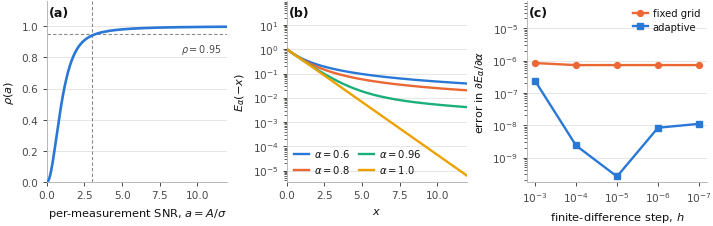

In [ ]:


fig, ax = plt.subplots(1, 3, figsize=(7.1, 2.35))
fig.subplots_adjust(wspace=0.33, left=0.065, right=0.995, top=0.97, bottom=0.20)

a = np.linspace(0.01, 12, 400)
ax[0].plot(a, [rician_rho(x) for x in a], color=C[0], lw=1.9, zorder=4)
ax[0].axhline(0.95, color=MUTED, ls=(0, (3, 2)), lw=0.8, zorder=2)
ax[0].axvline(3.0, color=MUTED, ls=(0, (3, 2)), lw=0.8, zorder=2)
ax[0].set_xlabel(r"per-measurement SNR, $a=A/\sigma$")
ax[0].set_ylabel(r"$\rho(a)$")
ax[0].set_xlim(0, 12)
ax[0].set_ylim(0, 1.0)
style(ax[0])
headroom(ax[0], 0.16)
panel(ax[0], "a")
ax[0].annotate(r"$\rho=0.95$", xy=(11.6, 0.90), ha="right", va="top",
               fontsize=6.9, color=INK2)


x = np.linspace(0.01, 12, 240)
for k, al in enumerate((0.6, 0.8, 0.96, 1.0)):
    ax[1].plot(x, [float(np.asarray(mittag_leffler(np.array([-xx]), al)).ravel()[0])
                   for xx in x], color=C[k], lw=1.7, zorder=4,
               label=rf"$\alpha={al}$")
ax[1].set_yscale("log")
ax[1].set_xlabel(r"$x$")
ax[1].set_ylabel(r"$E_\alpha(-x)$")
ax[1].set_xlim(0, 12)
style(ax[1])
headroom(ax[1], 0.30)
panel(ax[1], "b")
ax[1].legend(loc="lower left", ncol=2, columnspacing=0.9)

sw = V["fd_sweep"]
hs = sorted(sw.keys(), key=lambda s: -float(s))
xs = np.arange(len(hs))
ax[2].plot(xs, [sw[h]["grid"] for h in hs], "o-", color=C[1], lw=1.7, ms=4.2,
           zorder=4, label="fixed grid")
ax[2].plot(xs, [sw[h]["adaptive"] for h in hs], "s-", color=C[0], lw=1.7, ms=4.2,
           zorder=4, label="adaptive")
ax[2].set_yscale("log")
ax[2].set_xticks(xs)
ax[2].set_xticklabels([f"$10^{{{int(np.log10(float(h)))}}}$" for h in hs])
ax[2].set_xlabel(r"finite-difference step, $h$")
ax[2].set_ylabel(r"error in $\partial E_\alpha/\partial\alpha$")
style(ax[2])
headroom(ax[2], 0.45)
panel(ax[2], "c")
ax[2].legend(loc="upper right")      # top right, above both curves
savefig(fig, "fig1_numerics"); plt.show()

## 9. Theoretical precision (CRLB) at three published protocols

In [13]:
specs = [("mono", mono, theta_mono, ["S0", "ADC"], mono_jacobian),
         ("DKI", dki, theta_dki, ["S0", "MD", "MK"], dki_jacobian),
         ("SEM", sem, theta_sem, ["S0", "DDC", "alpha_s"], sem_jacobian),
         ("CTRW", ctrw, theta_ctrw, ["S0", "D_m", "alpha", "beta"], ctrw_jacobian)]
R1 = []
print(f"Rician noise, SNR at b=0 = {SNR_REF:.0f}, S0 normalised to 1\n")
for grp in ("malignant", "benign"):
    print(f"--- {grp} " + "-" * 58)
    print("  protocol".ljust(14) + "model".rjust(6) + "  dof   parameter CVs (%)")
    for pk in PROTO_ORDER:
        b = np.array(PROTOCOLS[pk]["b"])
        for nm, mdl, tfun, pnames, jac in specs:
            th = tfun(grp)
            cv, sd, cov, F = crlb(mdl, b, th, SIG, jac=jac)
            ev = np.linalg.eigvalsh(F)
            R1.append(dict(protocol=pk, group=grp, model=nm, names=pnames,
                           nmeas=len(b), dof=len(b) - len(th),
                           cond=float(ev.max() / max(ev.min(), 1e-300)),
                           cv=[float(x) for x in cv], theta=[float(x) for x in th]))
            txt = "  ".join(f"{n}={c:.1f}" for n, c in zip(pnames[1:], cv[1:]))
            print(f"  {PROTOCOLS[pk]['short']:<12}{nm:>6}{len(b)-len(th):>5}   {txt}")
    print()
RESULTS["R1"] = R1

Rician noise, SNR at b=0 = 30, S0 normalised to 1

--- malignant ----------------------------------------------------------
  protocol     model  dof   parameter CVs (%)
  7-point       mono    5   ADC=5.8
  7-point        DKI    4   MD=8.8  MK=9.5
  7-point        SEM    4   DDC=8.0  alpha_s=10.6
  7-point       CTRW    3   D_m=19.0  alpha=42.4  beta=36.9
  9-point       mono    7   ADC=5.3
  9-point        DKI    6   MD=9.9  MK=24.0
  9-point        SEM    6   DDC=7.2  alpha_s=9.6
  9-point       CTRW    5   D_m=14.8  alpha=42.2  beta=23.1
  13-point      mono   11   ADC=5.2
  13-point       DKI   10   MD=7.4  MK=10.6
  13-point       SEM   10   DDC=7.0  alpha_s=8.0
  13-point      CTRW    9   D_m=11.4  alpha=24.9  beta=17.1

--- benign ----------------------------------------------------------
  protocol     model  dof   parameter CVs (%)
  7-point       mono    5   ADC=6.7
  7-point        DKI    4   MD=8.7  MK=12.6
  7-point        SEM    4   DDC=10.2  alpha_s=12.9
  7-point      

#### 9b. The bound as an acquisition requirement (table S5)
SNR needed for CV(alpha) <= 20 %, and the number of independent repetitions of the complete acquisition needed for CV(alpha) <= 5 % at SNR 30, malignant values. Each repetition is assumed to measure the same parameter vector with independent noise, so this is not a number of voxels that could simply be averaged.

In [14]:
th = theta_ctrw("malignant")
R_req = {}
print(f"{'protocol':<12}{'CV(alpha) at SNR 30':>21}{'SNR for CV <= 20 %':>20}{'repetitions for CV <= 5 %':>27}")
for pk in PROTO_ORDER:
    b = np.array(PROTOCOLS[pk]["b"], float)
    cv30 = crlb(ctrw, b, th, SIG, jac=ctrw_jacobian)[0][2]
    snr_need = next(s for s in range(5, 400) if crlb(ctrw, b, th, 1.0 / s, jac=ctrw_jacobian)[0][2] <= 20.0)
    n_rep = int(np.ceil((cv30 / 5.0) ** 2))            # CV falls as 1/sqrt(number of repetitions)
    R_req[pk] = dict(cv_at_snr30=float(cv30), snr_for_cv20=int(snr_need), repetitions_for_cv5=n_rep)
    print(f"{SHORT[pk]:<12}{cv30:>20.1f}%{snr_need:>20d}{n_rep:>27d}")
RESULTS["R1_requirements"] = R_req

protocol      CV(alpha) at SNR 30  SNR for CV <= 20 %  repetitions for CV <= 5 %
7-point                     42.4%                  64                         72
9-point                     42.2%                  64                         72
13-point                    24.9%                  38                         25


### Figure 2: theoretical precision by model and protocol

  saved nb_output/fig2_precision.png


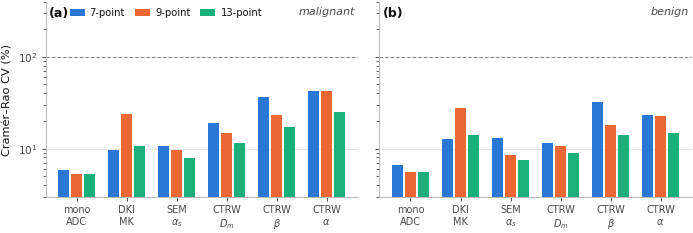

In [15]:
R1 = R1
pick = [("mono", 1, "ADC"), ("DKI", 2, "MK"), ("SEM", 2, r"$\alpha_s$"),
        ("CTRW", 1, r"$D_m$"), ("CTRW", 3, r"$\beta$"), ("CTRW", 2, r"$\alpha$")]
fig, ax = plt.subplots(1, 2, figsize=(7.1, 2.6), sharey=True)
fig.subplots_adjust(wspace=0.07, left=0.085, right=0.995, top=0.97, bottom=0.22)
w = 0.26
for gi, grp in enumerate(("malignant", "benign")):
    A = ax[gi]
    for pi, pk in enumerate(PROTO_ORDER):
        vals = [next(r for r in R1 if r["protocol"] == pk and r["group"] == grp
                     and r["model"] == m)["cv"][i] for m, i, _ in pick]
        A.bar(np.arange(len(pick)) + (pi - 1) * w, vals, w * 0.88, color=C[pi],
              zorder=3, label=SHORT[pk] if gi == 0 else None, linewidth=0)
    A.axhline(100, color=MUTED, ls=(0, (3, 2)), lw=0.8, zorder=2)
    A.set_yscale("log")
    A.set_ylim(3, 400)
    A.set_xticks(np.arange(len(pick)))
    A.set_xticklabels([f"{m}\n{n}" for m, _, n in pick], fontsize=7.0)
    A.set_xlim(-0.62, len(pick) - 0.38)
    style(A)
    panel(A, "ab"[gi])
    A.text(0.99, 0.975, grp, transform=A.transAxes, ha="right", va="top",
           fontsize=8.0, color=INK2, style="italic")
ax[0].set_ylabel("Cramér–Rao CV (%)")
ax[0].legend(loc="upper left", ncol=3, bbox_to_anchor=(0.055, 1.005),
             columnspacing=1.0)
savefig(fig, "fig2_precision"); plt.show()

## 10. Fisher eigenstructure and parameter correlation



In [ ]:
R2 = []
for pk in PROTO_ORDER:
    b = np.array(PROTOCOLS[pk]["b"])
    for grp in ("malignant", "benign"):
        th = np.asarray(theta_ctrw(grp), float)
        cv, sd, cov, F = crlb(ctrw, b, th, SIG, jac=ctrw_jacobian)
        Fn = np.diag(th) @ F @ np.diag(th)
        wr = np.linalg.eigvalsh(F)
        wn, Vn = np.linalg.eigh(Fn)
        v = Vn[:, 0]
        if v[2] < 0:
            v = -v
        v = v / np.abs(v).max()
        covn = np.linalg.pinv(Fn, rcond=1e-14)
        Cn = correlation_from_cov(covn)
        R2.append(dict(protocol=pk, group=grp,
                       eig=[float(x) for x in np.sort(wn)],
                       eig_raw=[float(x) for x in np.sort(wr)],
                       cond_norm=float(wn.max() / wn.min()),
                       cond_raw=float(wr.max() / wr.min()),
                       null_vec=[float(x) for x in v],
                       corr=[[float(x) for x in r] for r in Cn],
                       cv=[float(x) for x in cv]))
        if grp == "malignant":
            print(f"{PROTOCOLS[pk]['short']:<12} condition number: raw {wr.max()/wr.min():.2e}"
                  f"   normalised {wn.max()/wn.min():.0f}")
            print("   normalised eigenvalues: " + "  ".join(f"{x:.3f}" for x in np.sort(wn)))
            print("   least-informative eigenvector (S0, D_m, alpha, beta):")
            for n_, x_ in zip(["S0   ", "D_m  ", "alpha", "beta "], v):
                print(f"      {n_} {x_:+.4f}  " + "#" * int(round(34 * abs(x_))))
            print(f"   corr(alpha,beta)={Cn[2,3]:+.3f}   corr(D_m,alpha)={Cn[1,2]:+.3f}\n")

# the bound for (S0, alpha, beta) with D_m held fixed
def cond_crlb(b, th, sigma=None):
    F = fisher(ctrw, b, th, SIG if sigma is None else sigma, jac=ctrw_jacobian)
    idx = [0, 2, 3]
    cov = np.linalg.pinv(F[np.ix_(idx, idx)], rcond=1e-14)
    sd = np.sqrt(np.maximum(np.diag(cov), 0))
    return [100 * sd[k] / abs(th[i]) for k, i in enumerate(idx)], correlation_from_cov(cov)[1, 2]

R2c = []
print(f"{'protocol':<12}{'tissue':<11}{'CV(a) 4-par':>12}{'CV(a) Dm fix':>14}{'CV(b) Dm fix':>14}")
for pk in PROTO_ORDER:
    b = np.array(PROTOCOLS[pk]["b"])
    for grp in ("malignant", "benign"):
        th = theta_ctrw(grp)
        cv4 = crlb(ctrw, b, th, SIG, jac=ctrw_jacobian)[0]
        cv3, r = cond_crlb(b, th)
        R2c.append(dict(protocol=pk, group=grp, cv_joint=[float(x) for x in cv4],
                        cv_cond=[float(x) for x in cv3], corr_cond=float(r)))
        print(f"{PROTOCOLS[pk]['short']:<12}{grp:<11}{cv4[2]:12.1f}{cv3[1]:14.1f}{cv3[2]:14.1f}")
RESULTS["R2"], RESULTS["R2_conditional"] = R2, R2c

7-point      condition number: raw 9.60e+07   normalised 567
   normalised eigenvalues: 2.960  85.732  343.769  1678.108
   least-informative eigenvector (S0, D_m, alpha, beta):
      S0    +0.0061  
      D_m   -0.4044  ##############
      alpha +1.0000  ##################################
      beta  -0.8568  #############################
   corr(alpha,beta)=-0.957   corr(D_m,alpha)=-0.909

9-point      condition number: raw 8.32e+07   normalised 923
   normalised eigenvalues: 4.159  106.374  227.210  3838.377
   least-informative eigenvector (S0, D_m, alpha, beta):
      S0    +0.0324  #
      D_m   -0.3103  ###########
      alpha +1.0000  ##################################
      beta  -0.5157  ##################
   corr(alpha,beta)=-0.904   corr(D_m,alpha)=-0.869

13-point     condition number: raw 3.45e+07   normalised 589
   normalised eigenvalues: 10.586  131.334  351.511  6230.113
   least-informative eigenvector (S0, D_m, alpha, beta):
      S0    +0.0643  ##
      D_m   -0.3

#### 10b. Bound on alpha when beta is known
How much of the marginal bound on alpha comes from its coupling with beta (section 4.3).

In [17]:
th = np.array(theta_ctrw("malignant"))
R2b = {}
print(f"{'protocol':<12}{'four-parameter':>16}{'beta known':>12}{'all others known':>18}")
for pk in PROTO_ORDER:
    b = np.array(PROTOCOLS[pk]["b"], float)
    cv4, _, _, F = crlb(ctrw, b, th, SIG, jac=ctrw_jacobian)
    keep = [0, 1, 2]                                   # S0, D_m and alpha unknown, beta known
    cv_bk = 100 * np.sqrt(np.linalg.inv(F[np.ix_(keep, keep)])[2, 2]) / th[2]
    cv_only = 100 * np.sqrt(1.0 / F[2, 2]) / th[2]
    R2b[pk] = dict(cv4=float(cv4[2]), beta_known=float(cv_bk), alpha_only=float(cv_only))
    print(f"{SHORT[pk]:<12}{cv4[2]:>15.1f}%{cv_bk:>11.1f}%{cv_only:>17.1f}%")
RESULTS["R2_beta_known"] = R2b

protocol      four-parameter  beta known  all others known
7-point                42.4%       12.3%              7.7%
9-point                42.2%       18.1%             13.5%
13-point               24.9%       11.9%              8.9%


### Figure 3: Fisher eigenstructure and the least-informative direction

  saved nb_output/fig3_eigen.png


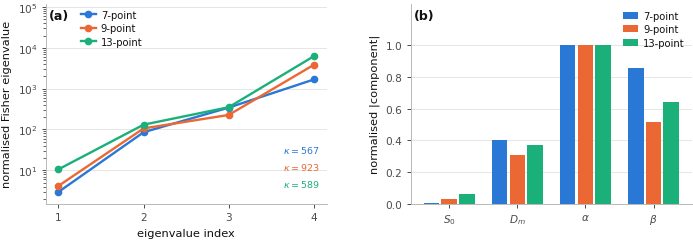

In [18]:
"""Eigenstructure in the dimensionless coordinates phi_j = log(theta_j/theta_j0)."""
R = {r["protocol"]: r for r in R2 if r["group"] == "malignant"}
fig, ax = plt.subplots(1, 2, figsize=(7.1, 2.6))
fig.subplots_adjust(wspace=0.30, left=0.085, right=0.995, top=0.97, bottom=0.20)

for pi, pk in enumerate(PROTO_ORDER):
    ax[0].plot(range(1, 5), sorted(R[pk]["eig"]), "o-", color=C[pi], lw=1.7, ms=4.5,
               zorder=4, label=SHORT[pk])
ax[0].set_yscale("log")
ax[0].set_xticks(range(1, 5))
ax[0].set_xlabel("eigenvalue index")
ax[0].set_ylabel("normalised Fisher eigenvalue")
ax[0].set_ylim(1.5, 1.2e5)
style(ax[0])
panel(ax[0], "a")
ax[0].legend(loc="upper left", bbox_to_anchor=(0.10, 1.005))
for pi, pk in enumerate(PROTO_ORDER):
    ax[0].text(0.975, 0.30 - 0.085 * pi, rf"$\kappa={R[pk]['cond_norm']:.0f}$",
               transform=ax[0].transAxes, ha="right", va="top",
               fontsize=6.8, color=C[pi], zorder=6)

names = [r"$S_0$", r"$D_m$", r"$\alpha$", r"$\beta$"]
w = 0.26
for pi, pk in enumerate(PROTO_ORDER):
    ax[1].bar(np.arange(4) + (pi - 1) * w, np.abs(R[pk]["null_vec"]), w * 0.88,
              color=C[pi], zorder=3, label=SHORT[pk], linewidth=0)
ax[1].set_xticks(range(4))
ax[1].set_xticklabels(names)
ax[1].set_ylabel("normalised |component|")
ax[1].set_ylim(0, 1.0)
ax[1].set_yticks([0, 0.2, 0.4, 0.6, 0.8, 1.0])
style(ax[1])
headroom(ax[1], 0.26)
panel(ax[1], "b")
ax[1].legend(loc="upper right", ncol=1)
savefig(fig, "fig3_eigen"); plt.show()

## 11. Dependence of the bound on the assumed parameter vector

In [19]:
n_grid = 26
A_ = np.linspace(*PARAM_GRID["alpha"], n_grid)
B_ = np.linspace(*PARAM_GRID["beta"], n_grid)
Dm_fix = HE2025["malignant"]["CTRW_Dm"][0]
surf, frac = {}, {}
t0 = time.time()
for pk in PROTO_ORDER:
    bb = np.array(PROTOCOLS[pk]["b"]); Z = np.zeros((n_grid, n_grid))
    for i, al in enumerate(A_):
        for j, be in enumerate(B_):
            Z[i, j] = crlb(ctrw, bb, [1.0, Dm_fix, al, be], SIG, jac=ctrw_jacobian)[0][2]
    surf[pk] = Z; frac[pk] = float(100.0 * np.mean(Z > 100.0))
    print(f"  {PROTOCOLS[pk]['short']:<12} CV(alpha) spans {Z.min():7.1f} % - {Z.max():8.1f} %"
          f"   above 100 % on {frac[pk]:5.1f} % of the rectangle")
print(f"\n  ({time.time()-t0:.0f} s)")
RESULTS["R3"] = dict(alpha=A_.tolist(), beta=B_.tolist(),
                     surfaces={k: v.tolist() for k, v in surf.items()}, frac_above_100=frac)

  7-point      CV(alpha) spans    21.4 % -    461.5 %   above 100 % on  41.6 % of the rectangle
  9-point      CV(alpha) spans    33.2 % -    165.2 %   above 100 % on  17.0 % of the rectangle
  13-point     CV(alpha) spans    17.3 % -    111.4 %   above 100 % on   1.0 % of the rectangle

  (35 s)


#### 11b. Dependence of the bound on D_m


In [20]:
Zm = {pk: np.array(RESULTS["R3"]["surfaces"][pk]) for pk in PROTO_ORDER}
Dm_ben = HE2025["benign"]["CTRW_Dm"][0]
Zb = {}
for pk in PROTO_ORDER:
    bb = np.array(PROTOCOLS[pk]["b"], float); Z = np.zeros((n_grid, n_grid))
    for i, al in enumerate(A_):
        for j, be in enumerate(B_):
            Z[i, j] = crlb(ctrw, bb, [1.0, Dm_ben, al, be], SIG, jac=ctrw_jacobian)[0][2]
    Zb[pk] = Z
for lab, Zs in (("malignant D_m", Zm), ("benign D_m", Zb)):
    print(f"  {lab}")
    for pk in PROTO_ORDER:
        Z = Zs[pk]
        print(f"    {SHORT[pk]:<11}CV(alpha) {Z.min():6.1f} to {Z.max():6.1f} %   above 50 %: {100*np.mean(Z > 50):5.1f} %"
              f"   above 100 %: {100*np.mean(Z > 100):5.1f} %")
    best = (Zs["Lin2023_13"] <= Zs["Ji2023_7"]) & (Zs["Lin2023_13"] <= Zs["He2025_9"])
    print(f"    thirteen-point protocol smallest at every grid point: {bool(best.all())}\n")
print("  D_m sweep at the published (alpha, beta):")
sweep = []
for grp in ("malignant", "benign"):
    t = theta_ctrw(grp)
    for Dm in (0.70e-3, 0.86e-3, 1.00e-3, 1.29e-3, 1.60e-3):
        cvs = [crlb(ctrw, np.array(PROTOCOLS[pk]["b"], float), [1.0, Dm, t[2], t[3]], SIG,
                    jac=ctrw_jacobian)[0][2] for pk in PROTO_ORDER]
        sweep.append(dict(group=grp, Dm=Dm, cv_alpha=[float(x) for x in cvs]))
        print(f"    {grp:<9} D_m = {Dm*1e3:.2f}e-3 mm2/s : CV(alpha) = " + ", ".join(f"{x:5.1f}" for x in cvs) + " %")
RESULTS["R3_benign_Dm"] = dict(surfaces={k: v.tolist() for k, v in Zb.items()}, sweep=sweep)

  malignant D_m
    7-point    CV(alpha)   21.4 to  461.5 %   above 50 %:  76.2 %   above 100 %:  41.6 %
    9-point    CV(alpha)   33.2 to  165.2 %   above 50 %:  70.1 %   above 100 %:  17.0 %
    13-point   CV(alpha)   17.3 to  111.4 %   above 50 %:  36.8 %   above 100 %:   1.0 %
    thirteen-point protocol smallest at every grid point: True

  benign D_m
    7-point    CV(alpha)   17.0 to  508.8 %   above 50 %:  65.8 %   above 100 %:  39.2 %
    9-point    CV(alpha)   17.3 to  144.2 %   above 50 %:  41.9 %   above 100 %:   5.5 %
    13-point   CV(alpha)   13.8 to   98.3 %   above 50 %:  24.6 %   above 100 %:   0.0 %
    thirteen-point protocol smallest at every grid point: True

  D_m sweep at the published (alpha, beta):
    malignant D_m = 0.70e-3 mm2/s : CV(alpha) =  53.1,  55.2,  31.5 %
    malignant D_m = 0.86e-3 mm2/s : CV(alpha) =  42.4,  42.2,  24.9 %
    malignant D_m = 1.00e-3 mm2/s : CV(alpha) =  36.5,  34.9,  21.2 %
    malignant D_m = 1.29e-3 mm2/s : CV(alpha) =  29.3, 

## 12. Monte Carlo: sequential against joint fitting

In [21]:
SEEDS = (20260101, 20260202, 20260303, 20260404, 20260505)
N_MC = 4000


def wilson(k, n, z=1.96):
    if n == 0:
        return (0.0, 0.0)
    p = k / n; d = 1 + z * z / n
    c = (p + z * z / (2 * n)) / d
    h = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return (100 * max(0.0, c - h), 100 * min(1.0, c + h))


MC_CACHE = os.path.join(OUTDIR, "mc_cache")
os.makedirs(MC_CACHE, exist_ok=True)


def cached_blocks(key, compute):
    """Each Monte Carlo condition is saved to nb_output/mc_cache as soon as it finishes, so an
    interrupted run resumes where it stopped. Delete the folder to recompute every condition."""
    import hashlib
    path = os.path.join(MC_CACHE, hashlib.sha1(repr(key).encode()).hexdigest()[:20] + ".npy")
    if os.path.exists(path):
        return list(np.load(path))
    blocks = compute()
    np.save(path[:-4] + "_tmp.npy", np.array(blocks))
    os.replace(path[:-4] + "_tmp.npy", path)
    return blocks


def run_condition(b, theta, n_total=N_MC, method="sequential", sigma=None, b_lowmax=1000.0):
    """Fit n_total noise realisations; returns one array per seed block."""
    sigma = SIG if sigma is None else sigma
    key = ("least_squares", [round(float(x), 6) for x in b], [float(x) for x in theta],
           int(n_total), method, float(sigma), float(b_lowmax), SEEDS)
    return cached_blocks(key, lambda: _run_condition(b, theta, n_total, method, sigma, b_lowmax))


def _run_condition(b, theta, n_total, method, sigma, b_lowmax):
    per = n_total // len(SEEDS)
    S = ctrw(b, *theta)
    blocks = []
    for seed in SEEDS:
        rng = np.random.default_rng(seed)
        out = np.empty((per, 4))
        for i in range(per):
            y = rice_sample(S, sigma, rng)
            try:
                if method == "joint":
                    p, _ = fit_ctrw_joint(b, y, theta)
                else:
                    p, _ = fit_ctrw_sequential(b, y, theta, b_lowmax=b_lowmax)
            except Exception:
                p = np.full(4, np.nan)
            out[i] = p
        blocks.append(out)
    return blocks


def summarise(blocks, theta):
    P = np.vstack(blocks)
    P = P[np.isfinite(P).all(axis=1)]
    n = len(P)
    res = dict(n=n)
    for k, idx, truth, lo, hi in (("Dm", 1, theta[1], CTRW_LO[1], CTRW_HI[1]),
                                  ("alpha", 2, theta[2], CTRW_LO[2], CTRW_HI[2]),
                                  ("beta", 3, theta[3], CTRW_LO[3], CTRW_HI[3])):
        v = P[:, idx]; span = hi - lo
        at_lo = float(np.mean(v <= lo + 1e-3 * span))
        at_hi = float(np.mean(v >= hi - 1e-3 * span))
        pin = float(np.mean((v <= lo + 1e-3 * span) | (v >= hi - 1e-3 * span)))
        res[k] = dict(truth=float(truth), mean=float(v.mean()), sd=float(v.std(ddof=1)),
                      bias_pct=float(100 * (v.mean() - truth) / truth),
                      cv_pct=float(100 * v.std(ddof=1) / truth),
                      rmse_pct=float(100 * np.sqrt(np.mean((v - truth) ** 2)) / truth),
                      pinned_pct=100 * pin, pinned_lower_pct=100 * at_lo,
                      pinned_upper_pct=100 * at_hi,
                      pinned_ci=wilson(int(round(pin * n)), n))
    res["corr_alpha_beta"] = float(np.corrcoef(P[:, 2], P[:, 3])[0, 1])
    return res


t0 = time.time()
R4 = {}
hdr = ("protocol".ljust(12) + "tissue".ljust(11) + "scheme".ljust(14) +
       "mean".rjust(7) + "bias%".rjust(8) + "SD".rjust(8) + "RMSE%".rjust(8) +
       "pin%".rjust(7) + "lo%".rjust(6) + "hi%".rjust(6) + "corr".rjust(8))
print(hdr); print("-" * len(hdr))
for pk in PROTO_ORDER:
    b = np.array(PROTOCOLS[pk]["b"])
    for grp in ("malignant", "benign"):
        th = theta_ctrw(grp)
        for meth, lab in (("joint", "joint"), ("sequential", "sequential")):
            r = summarise(run_condition(b, th, method=meth), th)
            R4[f"{pk}|{grp}|{meth}"] = r
            a = r["alpha"]
            print(f"{PROTOCOLS[pk]['short']:<12}{grp:<11}{lab:<14}{a['mean']:7.3f}"
                  f"{a['bias_pct']:8.1f}{a['sd']:8.3f}{a['rmse_pct']:8.1f}"
                  f"{a['pinned_pct']:7.1f}{a['pinned_lower_pct']:6.1f}"
                  f"{a['pinned_upper_pct']:6.1f}{r['corr_alpha_beta']:8.2f}")
print(f"\n({time.time()-t0:.0f} s)")
RESULTS["R4_montecarlo"] = R4

protocol    tissue     scheme           mean   bias%      SD   RMSE%   pin%   lo%   hi%    corr
-----------------------------------------------------------------------------------------------
7-point     malignant  joint           0.839   -12.6   0.199    24.2   44.8   0.0  44.8   -0.77
7-point     malignant  sequential      0.801   -16.5   0.095    19.3    4.5   0.0   4.5   -0.38
7-point     benign     joint           0.909    -8.2   0.112    13.9   41.4   0.0  41.4   -0.71
7-point     benign     sequential      0.943    -4.8   0.064     8.0   39.1   0.0  39.1   -0.64
9-point     malignant  joint           0.801   -16.5   0.249    30.8   43.8   0.0  43.8   -0.72
9-point     malignant  sequential      0.828   -13.7   0.119    18.5   17.7   0.0  17.7   -0.45
9-point     benign     joint           0.887   -10.4   0.154    18.7   44.4   0.0  44.4   -0.69
9-point     benign     sequential      0.950    -4.0   0.066     7.8   48.1   0.0  48.1   -0.53
13-point    malignant  joint           0

#### 12b. All three parameters at the headline conditions (table S3b)

In [22]:
print(f"{'protocol':<11}{'tissue':<11}{'scheme':<12}{'a bias%':>9}{'a pin%':>8}{'b bias%':>9}{'b pin%':>8}"
      f"{'Dm bias%':>10}{'Dm CV%':>8}")
for pk in PROTO_ORDER:
    for grp in ("malignant", "benign"):
        for meth in ("joint", "sequential"):
            r = RESULTS["R4_montecarlo"][f"{pk}|{grp}|{meth}"]
            print(f"{SHORT[pk]:<11}{grp:<11}{meth:<12}{r['alpha']['bias_pct']:+9.1f}{r['alpha']['pinned_pct']:8.1f}"
                  f"{r['beta']['bias_pct']:+9.1f}{r['beta']['pinned_pct']:8.1f}"
                  f"{r['Dm']['bias_pct']:+10.1f}{r['Dm']['cv_pct']:8.1f}")

protocol   tissue     scheme        a bias%  a pin%  b bias%  b pin%  Dm bias%  Dm CV%
7-point    malignant  joint           -12.6    44.8    +10.3    24.8      +7.7    16.2
7-point    malignant  sequential      -16.5     4.5    +13.4     6.9      +9.5     9.8
7-point    benign     joint            -8.2    41.4     +8.7    30.4      +3.9    11.6
7-point    benign     sequential       -4.8    39.1     +5.8    13.8      +0.5     8.1
9-point    malignant  joint           -16.5    43.8     +8.0    10.8      +9.5    17.3
9-point    malignant  sequential      -13.7    17.7     +7.0     2.0      +6.4     7.8
9-point    benign     joint           -10.4    44.4     +6.6    14.3      +5.3    12.1
9-point    benign     sequential       -4.0    48.1     +3.8     3.2      -1.2     6.5
13-point   malignant  joint           -11.2    40.4     +6.6     7.8      +6.4    14.4
13-point   malignant  sequential      -13.6    14.6     +7.9     1.6      +8.0     8.4
13-point   benign     joint            -7.9

### Figure 5: effect of the fitting scheme

  saved nb_output/fig5_fitting.png


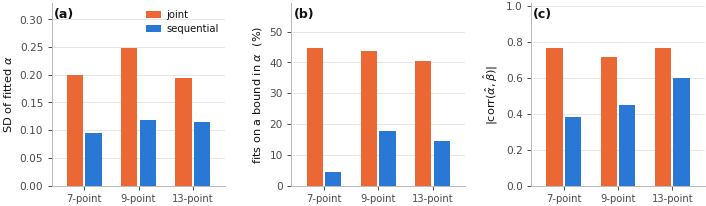

In [23]:
fig, ax = plt.subplots(1, 3, figsize=(7.1, 2.5))
fig.subplots_adjust(wspace=0.38, left=0.075, right=0.995, top=0.97, bottom=0.24)
labs, meths = ["joint", "sequential"], ["joint", "sequential"]
w = 0.34
specs = [("sd", r"SD of fitted $\alpha$", None),
         ("pinned_pct", r"fits on a bound in $\alpha$  (%)", None),
         ("corr", r"corr($\hat\alpha,\hat\beta$)", None)]
for j, (key, ylab, _) in enumerate(specs):
    for mi, meth in enumerate(meths):
        vals = []
        for pk in PROTO_ORDER:
            r = R4[f"{pk}|malignant|{meth}"]
            v = r["corr_alpha_beta"] if key == "corr" else r["alpha"][key]
            vals.append(abs(v) if key == "corr" else v)
        ax[j].bar(np.arange(3) + (mi - 0.5) * w, vals, w * 0.88,
                  color=C[1] if mi == 0 else C[0], zorder=3,
                  label=labs[mi] if j == 0 else None, linewidth=0)
    ax[j].set_xticks(range(3))
    ax[j].set_xticklabels([SHORT[p] for p in PROTO_ORDER], fontsize=7.2)
    ax[j].set_ylabel(ylab)
    ax[j].set_xlim(-0.6, 2.6)
    style(ax[j])
    headroom(ax[j], 0.26)
    panel(ax[j], "abc"[j])
ax[2].set_ylabel(r"$|$corr($\hat\alpha,\hat\beta$)$|$")
ax[0].legend(loc="upper right", ncol=1)
savefig(fig, "fig5_fitting"); plt.show()

## 13. Monte Carlo over the same parameter rectangle as the bound

In [ ]:
t0 = time.time()
GRID_N, GRID_REP = 26, 200
GRID_SEEDS = (20260101, 20260202, 20260303, 20260404)


def _map(fn, jobs):
    """Two worker processes where the platform forks, otherwise a plain loop."""
    try:
        from multiprocessing import Pool, get_start_method
        if get_start_method() != "fork":
            raise RuntimeError("no fork")
        with Pool(2) as pool:
            return pool.map(fn, jobs, chunksize=16)
    except Exception:
        return [fn(j) for j in jobs]


def _cell(args):
    b, al, be, seed, n, meth = args
    b = np.asarray(b, float)
    th = np.array([1.0, DM_, al, be])
    rng = np.random.default_rng(seed)
    S = ctrw(b, *th)
    out = np.empty((n, 4))
    for i in range(n):
        y = rice_sample(S, SIG, rng)
        try:
            if meth == "joint":
                p, _ = fit_ctrw_joint(b, y, th)
            else:
                p, _ = fit_ctrw_sequential(b, y, th, b_lowmax=1000.0)
        except Exception:
            p = np.full(4, np.nan)
        out[i] = p
    P = out[np.isfinite(out).all(axis=1)]
    if len(P) < 2:
        return dict(bias=np.nan, sd=np.nan, rmse=np.nan, pin=np.nan)
    v = P[:, 2]
    span = CTRW_HI[2] - CTRW_LO[2]
    return dict(bias=float(100 * (v.mean() - al) / al), sd=float(v.std(ddof=1)),
                rmse=float(100 * np.sqrt(np.mean((v - al) ** 2)) / al),
                pin=float(100 * np.mean((v <= CTRW_LO[2] + 1e-3 * span)
                                        | (v >= CTRW_HI[2] - 1e-3 * span))))
A_ = np.linspace(*PARAM_GRID["alpha"], GRID_N)
B_ = np.linspace(*PARAM_GRID["beta"], GRID_N)
DM_ = HE2025["malignant"]["CTRW_Dm"][0]
R3B = {"alpha": A_.tolist(), "beta": B_.tolist(), "n_rep": GRID_REP, "surfaces": {}}
cache = os.path.join(OUTDIR, "gridmc_malignantDm.json")
if os.path.exists(cache):
    R3B = json.load(open(cache))
    print(f"loaded {cache}\n")
else:
    per = GRID_REP // len(GRID_SEEDS)
    for pk in PROTO_ORDER:
        b = list(np.array(PROTOCOLS[pk]["b"]))
        for meth in ("sequential", "joint"):
            jobs = [(b, float(al), float(be), sd, per, meth)
                    for al in A_ for be in B_ for sd in GRID_SEEDS]
            res = _map(_cell, jobs)
            S = {k: np.zeros((GRID_N, GRID_N)) for k in ("bias", "sd", "rmse", "pin")}
            q = 0
            for i in range(GRID_N):
                for j in range(GRID_N):
                    blk = res[q:q + len(GRID_SEEDS)]; q += len(GRID_SEEDS)
                    for k in S:
                        S[k][i, j] = float(np.nanmean([x[k] for x in blk]))
            R3B["surfaces"][f"{pk}|{meth}"] = {k: S[k].tolist() for k in S}
    json.dump(R3B, open(cache, "w"))

print(f"{GRID_N}x{GRID_N} grid, {GRID_REP} realisations per point, both schemes, D_m at the malignant value.\n")
print(f"  {'protocol':<10}{'scheme':<14}{'bias %':>18}{'pinned %':>18}")
print("  " + "-" * 60)
for pk in PROTO_ORDER:
    for meth in ("sequential", "joint"):
        S = {k: np.array(v) for k, v in R3B["surfaces"][f"{pk}|{meth}"].items()}
        print(f"  {PROTOCOLS[pk]['short']:<10}{meth:<14}"
              f"{S['bias'].min():+8.1f} to {S['bias'].max():+7.1f}"
              f"{S['pin'].min():9.1f} to {S['pin'].max():7.1f}")
print(f"\n({time.time()-t0:.0f} s)")
RESULTS["R3B_grid_mc"] = R3B

26x26 grid, 200 realisations per point, both schemes, D_m at the malignant value.

  protocol  scheme                    bias %          pinned %
  ------------------------------------------------------------
  7-point   sequential       -27.2 to   +22.8      0.0 to    62.0
  7-point   joint            -23.1 to   +24.9     25.5 to    65.5
  9-point   sequential       -18.9 to   +22.4      0.0 to    51.5
  9-point   joint            -24.3 to   +13.5     17.0 to    63.0
  13-point  sequential       -20.0 to   +17.5      0.0 to    50.5
  13-point  joint            -20.0 to   +10.3      8.5 to    51.0

(6218 s)


### Figure 4: CRLB and fitted error over the same parameter rectangle

  saved nb_output/fig4_grid.png


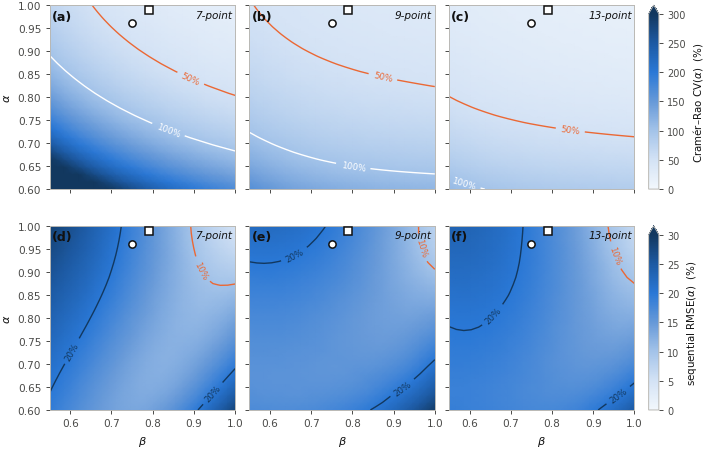

In [ ]:
R3 = RESULTS["R3"]
A = np.array(R3["alpha"]); B = np.array(R3["beta"])
Ag = np.array(R3B["alpha"]); Bg = np.array(R3B["beta"])
fig = plt.figure(figsize=(7.1, 4.55))
gs = fig.add_gridspec(2, 4, width_ratios=[1, 1, 1, 0.055],
                      left=0.072, right=0.93, top=0.975, bottom=0.085,
                      wspace=0.10, hspace=0.20)
rows = [(lambda pk: np.array(R3["surfaces"][pk]), A, B, 300.0, [50, 100],
         r"Cramér–Rao CV($\alpha$)  (%)", "abc"),
        (lambda pk: np.array(R3B["surfaces"][f"{pk}|sequential"]["rmse"]), Ag, Bg, 30.0,
         [10, 20], r"sequential RMSE($\alpha$)  (%)", "def")]
for r, (getZ, A_, B_, vmax, lv, label, letters) in enumerate(rows):
    for i, pk in enumerate(PROTO_ORDER):
        ax = fig.add_subplot(gs[r, i])
        Z = getZ(pk)
        im = ax.pcolormesh(B_, A_, np.clip(Z, 0, vmax), cmap=SEQ, vmin=0, vmax=vmax,
                           shading="gouraud", rasterized=True)
        cs = ax.contour(B_, A_, Z, levels=lv, linewidths=1.0,
                        colors=["#eb6834", "white"] if r == 0 else ["#eb6834", "#12385f"])
        ax.clabel(cs, inline=True, fontsize=6.2, fmt="%d%%")
        for grp, mk in (("malignant", "o"), ("benign", "s")):
            th = theta_ctrw(grp)
            ax.plot(th[3], th[2], mk, mfc="white", mec="#111111", ms=5.2, mew=1.1, zorder=5)
        ax.set_xticks([0.6, 0.7, 0.8, 0.9, 1.0])
        if r == 1:
            ax.set_xlabel(r"$\beta$")
        else:
            ax.set_xticklabels([])
        if i:
            ax.set_yticklabels([])
        else:
            ax.set_ylabel(r"$\alpha$")
        panel(ax, letters[i])
        ax.text(0.985, 0.975, SHORT[pk], transform=ax.transAxes, ha="right", va="top",
                fontsize=7.6, color=INK, zorder=6, style="italic")
    cax = fig.add_subplot(gs[r, 3])
    cb = fig.colorbar(im, cax=cax, extend="max")
    cb.set_label(label, labelpad=4, fontsize=7.4)
    cb.ax.tick_params(labelsize=7.0)
savefig(fig, "fig4_grid"); plt.show()

#### 13b. CRLB against the empirical SD over the rectangle


In [26]:
AL = np.repeat(np.array(R3B["alpha"])[:, None], GRID_N, axis=1)
ratios = []
for pk in PROTO_ORDER:
    s = R3B["surfaces"][f"{pk}|sequential"]; j = R3B["surfaces"][f"{pk}|joint"]
    sd_pct = 100 * np.array(s["sd"]) / AL
    r = Zm[pk] / sd_pct; ratios.append(r)
    bias, pin = np.array(s["bias"]), np.array(s["pin"])
    print(f"  {SHORT[pk]:<10} CRLB / empirical SD {r.min():5.2f} to {r.max():5.1f}"
          f" | bias < 0 on {100*np.mean(bias < 0):4.1f} % | pinned < 5 % on {100*np.mean(pin < 5):4.1f} %"
          f" | pinned > 25 % on {100*np.mean(pin > 25):4.1f} % (true alpha >= {AL[pin > 25].min():.3f})"
          f" | median RMSE joint {np.median(j['rmse']):.1f} % / sequential {np.median(s['rmse']):.1f} %")
print(f"  all protocols: CRLB / empirical SD {np.min(ratios):.2f} to {np.max(ratios):.1f}")

  7-point    CRLB / empirical SD  3.55 to  33.3 | bias < 0 on 77.4 % | pinned < 5 % on 79.4 % | pinned > 25 % on  5.3 % (true alpha >= 0.888) | median RMSE joint 34.9 % / sequential 15.6 %
  9-point    CRLB / empirical SD  3.42 to   9.6 | bias < 0 on 71.9 % | pinned < 5 % on 47.6 % | pinned > 25 % on  7.1 % (true alpha >= 0.856) | median RMSE joint 39.5 % / sequential 16.4 %
  13-point   CRLB / empirical SD  2.06 to   5.9 | bias < 0 on 83.9 % | pinned < 5 % on 60.5 % | pinned > 25 % on  3.7 % (true alpha >= 0.920) | median RMSE joint 35.0 % / sequential 17.9 %
  all protocols: CRLB / empirical SD 2.06 to 33.3


#### 13c. Monte Carlo over the rectangle at the benign D_m


In [27]:
t0 = time.time()
cache = os.path.join(OUTDIR, "gridmc_benignDm.json")
if os.path.exists(cache):
    R3Bb = json.load(open(cache))
    print(f"loaded {cache}")
else:
    DM_ = HE2025["benign"]["CTRW_Dm"][0]            # _cell() of section 13 reads DM_
    R3Bb = {"alpha": A_.tolist(), "beta": B_.tolist(), "n_rep": GRID_REP, "surfaces": {}}
    per = GRID_REP // len(GRID_SEEDS)
    for pk in PROTO_ORDER:
        b = list(np.array(PROTOCOLS[pk]["b"]))
        for meth in ("sequential", "joint"):
            jobs = [(b, float(al), float(be), sd, per, meth) for al in A_ for be in B_ for sd in GRID_SEEDS]
            res = _map(_cell, jobs)
            S = {k: np.zeros((GRID_N, GRID_N)) for k in ("bias", "sd", "rmse", "pin")}
            q = 0
            for i in range(GRID_N):
                for j in range(GRID_N):
                    blk = res[q:q + len(GRID_SEEDS)]; q += len(GRID_SEEDS)
                    for k in S:
                        S[k][i, j] = float(np.nanmean([x[k] for x in blk]))
            R3Bb["surfaces"][f"{pk}|{meth}"] = {k: S[k].tolist() for k in S}
    DM_ = HE2025["malignant"]["CTRW_Dm"][0]
    json.dump(R3Bb, open(cache, "w"))
print(f"\n  {'protocol':<10}{'scheme':<12}{'bias %':>18}{'pinned %':>16}{'RMSE %':>16}")
for pk in PROTO_ORDER:
    for meth in ("sequential", "joint"):
        S = {k: np.array(v) for k, v in R3Bb["surfaces"][f"{pk}|{meth}"].items()}
        print(f"  {SHORT[pk]:<10}{meth:<12}{S['bias'].min():+8.1f} to {S['bias'].max():+6.1f}"
              f"{S['pin'].min():7.1f} to {S['pin'].max():5.1f}{S['rmse'].min():7.1f} to {S['rmse'].max():5.1f}")
print()
rb = []
for pk in PROTO_ORDER:
    s = {k: np.array(v) for k, v in R3Bb["surfaces"][f"{pk}|sequential"].items()}
    j = {k: np.array(v) for k, v in R3Bb["surfaces"][f"{pk}|joint"].items()}
    r = np.array(RESULTS["R3_benign_Dm"]["surfaces"][pk]) / (100 * s["sd"] / AL); rb.append(r)
    print(f"  {SHORT[pk]:<10} sequential SD < joint SD on {100*np.mean(s['sd'] < j['sd']):5.1f} %"
          f" | sequential RMSE < joint on {100*np.mean(s['rmse'] < j['rmse']):5.1f} %"
          f" | bias < 0 on {100*np.mean(s['bias'] < 0):4.1f} % (only for alpha >= {AL[s['bias'] < 0].min():.3f})"
          f" | sequential pinned > 25 % on {100*np.mean(s['pin'] > 25):4.1f} % (alpha >= {AL[s['pin'] > 25].min():.2f})"
          f" | median pinned sequential {np.median(s['pin']):.1f} % / joint {np.median(j['pin']):.1f} %"
          f" | median RMSE joint {np.median(j['rmse']):.1f} % / sequential {np.median(s['rmse']):.1f} %")
print(f"  CRLB (benign D_m) / empirical SD {np.min(rb):.2f} to {np.max(rb):.1f}")
print(f"\n({time.time()-t0:.0f} s)")
RESULTS["R3B_grid_mc_benignDm"] = R3Bb


  protocol  scheme                  bias %        pinned %          RMSE %
  7-point   sequential      -6.6 to  +40.2    3.0 to  47.0    4.1 to  42.4
  7-point   joint          -18.8 to  +22.3   19.0 to  51.0    5.2 to  53.0
  9-point   sequential      -5.1 to  +37.3    4.0 to  60.0    4.3 to  41.2
  9-point   joint          -18.9 to  +11.8    8.0 to  51.5    5.5 to  51.9
  13-point  sequential      -6.8 to  +28.8    1.5 to  43.0    5.2 to  33.4
  13-point  joint          -17.8 to   +7.8    2.5 to  38.0    6.2 to  44.3

  7-point    sequential SD < joint SD on 100.0 % | sequential RMSE < joint on  98.1 % | bias < 0 on 19.1 % (only for alpha >= 0.920) | sequential pinned > 25 % on 36.8 % (alpha >= 0.82) | median pinned sequential 19.0 % / joint 33.5 % | median RMSE joint 30.3 % / sequential 14.6 %
  9-point    sequential SD < joint SD on 100.0 % | sequential RMSE < joint on  97.9 % | bias < 0 on 16.6 % (only for alpha >= 0.936) | sequential pinned > 25 % on 40.7 % (alpha >= 0.76) | med

#### 13d. Summary of the Monte Carlo surfaces (tables S3e and S3g)


In [28]:
def surface_summary(G, title):
    print(title)
    print(f"  {'protocol':<10}{'scheme':<12}{'quantity':<12}{'min':>8}{'q1':>8}{'median':>8}{'q3':>8}{'max':>8}")
    out = {}
    for pk in PROTO_ORDER:
        for meth in ("sequential", "joint"):
            S = G["surfaces"][f"{pk}|{meth}"]
            for key, lab, fmt in (("bias", "bias (%)", "{:+.1f}"), ("sd", "SD", "{:.3f}"),
                                  ("rmse", "RMSE (%)", "{:.1f}"), ("pin", "pinned (%)", "{:.1f}")):
                v = np.array(S[key]).ravel()
                q = [float(v.min()), *map(float, np.percentile(v, [25, 50, 75])), float(v.max())]
                out[f"{pk}|{meth}|{key}"] = q
                print(f"  {SHORT[pk]:<10}{meth:<12}{lab:<12}" + "".join(f"{fmt.format(x):>8}" for x in q))
    return out


RESULTS["R3B_summary_malignantDm"] = surface_summary(R3B, "malignant D_m (table S3e)")
print()
RESULTS["R3B_summary_benignDm"] = surface_summary(R3Bb, "benign D_m (table S3g)")

malignant D_m (table S3e)
  protocol  scheme      quantity         min      q1  median      q3     max
  7-point   sequential  bias (%)       -27.2   -16.2    -9.0    -0.9   +22.8
  7-point   sequential  SD             0.044   0.080   0.084   0.091   0.098
  7-point   sequential  RMSE (%)         5.0    12.7    15.6    19.9    28.5
  7-point   sequential  pinned (%)       0.0     0.0     0.5     3.0    62.0
  7-point   joint       bias (%)       -23.1   -10.9    -3.8    +3.1   +24.9
  7-point   joint       SD             0.046   0.183   0.256   0.295   0.342
  7-point   joint       RMSE (%)         5.1    23.7    34.9    41.3    57.5
  7-point   joint       pinned (%)      25.5    31.5    37.5    42.5    65.5
  9-point   sequential  bias (%)       -18.9   -10.8    -5.2    +0.8   +22.4
  9-point   sequential  SD             0.063   0.107   0.112   0.114   0.119
  9-point   sequential  RMSE (%)         7.7    15.3    16.4    18.2    29.3
  9-point   sequential  pinned (%)       0.0     2

## 14. Monte Carlo over two coarse grids of assumed alpha and beta

#### 14a. First grid (table S3)


In [29]:
t0 = time.time()
R5a = {}
print(f"  {'protocol':<10}{'alpha':>6}{'beta':>6}  {'scheme':<12}{'mean':>7}{'bias%':>8}{'SD':>8}"
      f"{'pinned%':>9}{'corr':>7}")
print("  " + "-" * 73)
for pk in ("Ji2023_7", "Lin2023_13"):
    b = np.array(PROTOCOLS[pk]["b"])
    for a_t in (0.70, 0.85, 0.96):
        for b_t in (0.60, 0.75, 0.90):
            th = [1.0, HE2025["malignant"]["CTRW_Dm"][0], a_t, b_t]
            for meth in ("joint", "sequential"):
                r = summarise(run_condition(b, th, n_total=1000, method=meth), th)
                R5a[f"{pk}|{a_t}|{b_t}|{meth}"] = r
                a = r["alpha"]
                print(f"  {SHORT[pk]:<10}{a_t:>6.2f}{b_t:>6.2f}  {meth:<12}{a['mean']:7.3f}"
                      f"{a['bias_pct']:+8.1f}{a['sd']:8.3f}{a['pinned_pct']:9.1f}{r['corr_alpha_beta']:+7.2f}")
print(f"\n({time.time()-t0:.0f} s)")
RESULTS["R5_grid_first"] = R5a

  protocol   alpha  beta  scheme         mean   bias%      SD  pinned%   corr
  -------------------------------------------------------------------------
  7-point     0.70  0.60  joint         0.653    -6.8   0.325     39.2  -0.77
  7-point     0.70  0.60  sequential    0.586   -16.2   0.082      0.0  -0.26
  7-point     0.70  0.75  joint         0.667    -4.7   0.298     35.0  -0.81
  7-point     0.70  0.75  sequential    0.643    -8.2   0.087      0.0  -0.15
  7-point     0.70  0.90  joint         0.728    +4.0   0.240     28.4  -0.76
  7-point     0.70  0.90  sequential    0.722    +3.2   0.098      0.5  -0.15
  7-point     0.85  0.60  joint         0.701   -17.5   0.303     42.4  -0.81
  7-point     0.85  0.60  sequential    0.667   -21.5   0.083      0.0  -0.33
  7-point     0.85  0.75  joint         0.744   -12.4   0.262     38.1  -0.81
  7-point     0.85  0.75  sequential    0.732   -13.9   0.092      0.7  -0.28
  7-point     0.85  0.90  joint         0.834    -1.9   0.170     

#### 14b. Second grid, with terminations at the lower and upper limits counted separately (table S3c, figure S1)

In [30]:
t0 = time.time()
R5 = {}
ALPHAS = (0.70, 0.80, 0.90, 0.96)
BETAS = (0.65, 0.75, 0.85)
print("Boundary terminations in alpha as the assumed parameter vector is moved.")
print("1000 realisations per condition, D_m at the malignant value.")
print("Terminations are counted separately at the lower and the upper limit.\n")
for pk in ("Ji2023_7", "Lin2023_13"):
    b = np.array(PROTOCOLS[pk]["b"])
    print(f"--- {PROTOCOLS[pk]['short']}")
    print(f"{'':10}" + "".join(f"{'beta='+str(bt):>24}" for bt in BETAS))
    print(f"{'alpha':10}" + "".join(f"{'joint':>12}{'seq':>12}" for _ in BETAS))
    for a_t in ALPHAS:
        row = f"{a_t:<10.2f}"
        for b_t in BETAS:
            th = [1.0, HE2025["malignant"]["CTRW_Dm"][0], a_t, b_t]
            for meth in ("joint", "sequential"):
                r = summarise(run_condition(b, th, n_total=1000, method=meth), th)
                R5[f"{pk}|{a_t}|{b_t}|{meth}"] = r
                a = r["alpha"]
                row += f"{a['pinned_lower_pct']:5.1f}/{a['pinned_upper_pct']:<6.1f}"
        print(row)
    print()
print("Read as lower/upper. SD of fitted alpha, sequential scheme:")
for pk in ("Ji2023_7", "Lin2023_13"):
    for a_t in ALPHAS:
        vals = [R5[f"{pk}|{a_t}|{b_t}|sequential"]["alpha"]["sd"] for b_t in BETAS]
        print(f"  {PROTOCOLS[pk]['short']:<12} alpha={a_t}:  " + "  ".join(f"{v:.3f}" for v in vals))
print(f"\n({time.time()-t0:.0f} s)")
RESULTS["R5_grid"] = R5

Boundary terminations in alpha as the assumed parameter vector is moved.
1000 realisations per condition, D_m at the malignant value.
Terminations are counted separately at the lower and the upper limit.

--- 7-point
                         beta=0.65               beta=0.75               beta=0.85
alpha            joint         seq       joint         seq       joint         seq
0.70        0.0/37.8    0.0/0.0     0.0/35.0    0.0/0.0     0.0/31.3    0.0/0.2   
0.80        0.0/39.2    0.0/0.0     0.0/36.8    0.0/0.2     0.0/33.3    0.0/1.6   
0.90        0.0/42.9    0.0/0.4     0.0/40.0    0.0/1.7     0.0/37.7    0.0/6.8   
0.96        0.0/45.9    0.0/1.1     0.0/44.6    0.0/4.8     0.0/43.1    0.0/14.8  

--- 13-point
                         beta=0.65               beta=0.75               beta=0.85
alpha            joint         seq       joint         seq       joint         seq
0.70        0.0/21.2    0.0/0.8     0.0/18.0    0.0/1.0     0.0/15.9    0.0/1.0   
0.80        0.0/26.1  

## 15. Maximum b-value: CRLB against fitted accuracy

In [31]:
t0 = time.time()
DENSE = [0., 30., 50., 70., 100., 150., 200., 400., 600., 1000.,
         1500., 2000., 2500., 3000., 4000.]
LOWB = [0., 50., 100., 200., 400., 600., 1000.]   # identical at every b_max
BMAXES = (1500., 2000., 2500., 3000., 4000.)
GAMMA_, TE0_, T2_, G_REF = 2.675e8, 20e-3, 80.9e-3, 45e-3
th = theta_ctrw("malignant")


def bset_truncated(bmax):
    """(a) one dense acquisition truncated; the measurement count falls with b_max."""
    return np.array([x for x in DENSE if x <= bmax])


def bset_fixed_lowb(bmax, n_high=6):
    """(b) matched count: the same low-b block, only the high-b points move."""
    return np.array(LOWB + list(np.linspace(1000.0, bmax, n_high + 1)[1:]))


def te_for_b(b, G=G_REF):
    return TE0_ + (12.0 * (b * 1e6) / (GAMMA_ ** 2 * G ** 2)) ** (1.0 / 3.0)


R6 = {}
hdr = ("b_max".rjust(7) + "N".rjust(4) + "  scheme".ljust(16) + "CRLB4%".rjust(8) +
       "CRLBc%".rjust(8) + "bias%".rjust(8) + "SD".rjust(8) + "RMSE%".rjust(8) +
       "pin%".rjust(7) + "lo%".rjust(6) + "hi%".rjust(6) + "corr".rjust(8))


def sweep(tag, bset, sigma_of=None, note=""):
    print(note); print(hdr); print("-" * len(hdr))
    for bmax in BMAXES:
        b = bset(bmax)
        sig = SIG if sigma_of is None else sigma_of(bmax)
        cv4 = crlb(ctrw, b, th, sig, jac=ctrw_jacobian)[0][2]
        cv3 = cond_crlb(b, th, sigma=sig)[0][1]
        for meth, lab in (("joint", "joint"), ("sequential", "sequential")):
            r = summarise(run_condition(b, th, n_total=2000, method=meth, sigma=sig), th)
            r["crlb4"], r["crlb_cond"], r["n_bvalues"] = float(cv4), float(cv3), len(b)
            R6[f"{tag}|{bmax:.0f}|{meth}"] = r
            a = r["alpha"]
            print(f"{bmax:7.0f}{len(b):4d}  {lab:<14}{cv4:8.1f}{cv3:8.1f}{a['bias_pct']:8.1f}"
                  f"{a['sd']:8.3f}{a['rmse_pct']:8.1f}{a['pinned_pct']:7.1f}"
                  f"{a['pinned_lower_pct']:6.1f}{a['pinned_upper_pct']:6.1f}"
                  f"{r['corr_alpha_beta']:8.2f}")
    print()


sweep("trunc", bset_truncated,
      note="(a) simple truncation: the number of measurements falls from 15 to 11.\n")
sweep("matched", bset_fixed_lowb,
      note="(b) matched count, N = 13 throughout, identical low-b block.\n")
sweep("time", bset_fixed_lowb,
      sigma_of=lambda bm: SIG / float(np.exp(-(te_for_b(bm) - te_for_b(1500.0)) / T2_)),
      note=("(c) matched count with the TE-dependent signal penalty: the echo time needed for each\n"
            "range is applied as a T2 signal loss relative to b_max = 1500 s/mm2 at 45 mT/m.\n"))

print("Sequential RMSE in alpha (%), the three designs side by side:")
print("  b_max   truncated   matched N   TE penalty")
for bmax in BMAXES:
    print(f"  {bmax:5.0f}" + "".join(
        f"{R6[f'{t}|{bmax:.0f}|sequential']['alpha']['rmse_pct']:12.1f}"
        for t in ("trunc", "matched", "time")))
print(f"\n({time.time()-t0:.0f} s)")
RESULTS["R6_bmax"] = R6

(a) simple truncation: the number of measurements falls from 15 to 11.

  b_max   N  scheme          CRLB4%  CRLBc%   bias%      SD   RMSE%   pin%   lo%   hi%    corr
----------------------------------------------------------------------------------------------
   1500  11  joint             59.9    29.6   -21.5   0.302    38.1   50.2   5.2  45.1   -0.65
   1500  11  sequential        59.9    29.6   -18.4   0.136    23.2   16.3   0.0  16.3   -0.21
   2000  12  joint             40.5    20.6   -16.5   0.248    30.6   42.9   0.0  42.9   -0.71
   2000  12  sequential        40.5    20.6   -16.4   0.126    21.0   15.3   0.0  15.3   -0.39
   2500  13  joint             30.0    16.6   -12.9   0.210    25.4   42.0   0.0  42.0   -0.76
   2500  13  sequential        30.0    16.6   -14.5   0.118    19.0   14.5   0.0  14.5   -0.57
   3000  14  joint             23.6    14.2   -10.9   0.188    22.4   39.8   0.0  39.8   -0.80
   3000  14  sequential        23.6    14.2   -13.6   0.111    17.9   12.

#### 15b. Spatial order and diffusivity as the acquisition is truncated (tables S4 and S4b)


In [32]:
th = theta_ctrw("malignant")
crlb_all = {}
for tag, bset, head in (("trunc", bset_truncated, "(a) truncation, table S4"),
                        ("matched", bset_fixed_lowb, "(b) matched count, N = 13, table S4b")):
    print(f"\n{head}")
    print(f"{'b_max':>6}{'N':>4}  {'scheme':<12}{'CRLB b%':>9}{'b bias%':>9}{'b RMSE%':>9}{'b pin%':>8}"
          f"{'CRLB Dm%':>10}{'Dm bias%':>10}{'Dm RMSE%':>10}")
    for bmax in BMAXES:
        b = bset(bmax)
        cv = crlb(ctrw, b, th, SIG, jac=ctrw_jacobian)[0]
        crlb_all[f"{tag}|{bmax:.0f}"] = dict(S0=float(cv[0]), Dm=float(cv[1]), alpha=float(cv[2]), beta=float(cv[3]))
        for meth in ("joint", "sequential"):
            r = R6[f"{tag}|{bmax:.0f}|{meth}"]
            print(f"{bmax:6.0f}{len(b):4d}  {meth:<12}{cv[3]:9.1f}{r['beta']['bias_pct']:+9.1f}"
                  f"{r['beta']['rmse_pct']:9.1f}{r['beta']['pinned_pct']:8.1f}{cv[1]:10.1f}"
                  f"{r['Dm']['bias_pct']:+10.1f}{r['Dm']['rmse_pct']:10.1f}")
RESULTS["R6_bmax_crlb_all"] = crlb_all


(a) truncation, table S4
 b_max   N  scheme        CRLB b%  b bias%  b RMSE%  b pin%  CRLB Dm%  Dm bias%  Dm RMSE%
  1500  11  joint            25.2     +8.9     17.4     9.8      16.5     +12.7      23.9
  1500  11  sequential       25.2     +8.5     14.0     1.8      16.5      +8.3      11.9
  2000  12  joint            21.3     +8.0     16.6     9.1      14.3      +9.3      19.5
  2000  12  sequential       21.3     +8.2     13.8     1.5      14.3      +8.0      11.7
  2500  13  joint            18.8     +7.1     15.9     8.3      12.6      +7.5      17.0
  2500  13  sequential       18.8     +8.0     13.9     1.8      12.6      +8.1      11.7
  3000  14  joint            16.9     +6.3     14.9     6.9      11.4      +6.1      15.3
  3000  14  sequential       16.9     +7.6     13.4     1.1      11.4      +8.0      11.5
  4000  15  joint            14.9     +5.6     14.3     6.3       9.9      +4.4      12.6
  4000  15  sequential       14.9     +7.7     14.0     1.8       9.9     

### Figure 6: CRLB and fitted accuracy as the acquisition is truncated

  saved nb_output/fig6_bmax.png


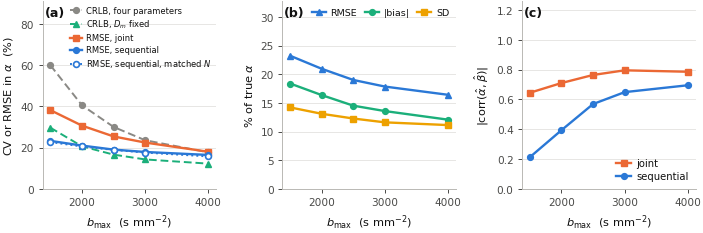

In [33]:
bm = [1500., 2000., 2500., 3000., 4000.]
fig, ax = plt.subplots(1, 3, figsize=(7.1, 2.5))
fig.subplots_adjust(wspace=0.38, left=0.075, right=0.995, top=0.97, bottom=0.22)

crlb4_ = [R6[f"trunc|{b:.0f}|sequential"]["crlb4"] for b in bm]
cond = [R6[f"trunc|{b:.0f}|sequential"]["crlb_cond"] for b in bm]
rm_s = [R6[f"trunc|{b:.0f}|sequential"]["alpha"]["rmse_pct"] for b in bm]
rm_j = [R6[f"trunc|{b:.0f}|joint"]["alpha"]["rmse_pct"] for b in bm]
ax[0].plot(bm, crlb4_, "o", ls=(0, (4, 2)), color=MUTED, lw=1.4, ms=4.2, zorder=3,
           label="CRLB, four parameters")
ax[0].plot(bm, cond, "^", ls=(0, (4, 2)), color=C[2], lw=1.4, ms=4.4, zorder=3,
           label=r"CRLB, $D_m$ fixed")
ax[0].plot(bm, rm_j, "s-", color=C[1], lw=1.7, ms=4.2, zorder=4, label="RMSE, joint")
ax[0].plot(bm, rm_s, "o-", color=C[0], lw=1.7, ms=4.2, zorder=4, label="RMSE, sequential")
rm_m = [R6[f"matched|{b:.0f}|sequential"]["alpha"]["rmse_pct"] for b in bm]
ax[0].plot(bm, rm_m, "o", ls=(0, (1, 1.6)), color=C[0], lw=1.4, ms=4.2, zorder=5,
           mfc="white", mew=1.2, label=r"RMSE, sequential, matched $N$")
ax[0].set_xlabel(r"$b_{\max}$  (s mm$^{-2}$)")
ax[0].set_ylabel(r"CV or RMSE in $\alpha$  (%)")
ax[0].set_ylim(0, 65)
style(ax[0])
headroom(ax[0], 0.40)
panel(ax[0], "a")
ax[0].legend(loc="upper right", fontsize=6.0, handlelength=1.5, handletextpad=0.4, borderaxespad=0.2)

tru = theta_ctrw("malignant")[2]
bias = [abs(R6[f"trunc|{b:.0f}|sequential"]["alpha"]["bias_pct"]) for b in bm]
sd = [100 * R6[f"trunc|{b:.0f}|sequential"]["alpha"]["sd"] / tru for b in bm]
ax[1].plot(bm, rm_s, "^-", color=C[0], lw=1.7, ms=4.4, zorder=4, label="RMSE")
ax[1].plot(bm, bias, "o-", color=C[2], lw=1.7, ms=4.2, zorder=4, label="|bias|")
ax[1].plot(bm, sd, "s-", color=C[3], lw=1.7, ms=4.2, zorder=4, label="SD")
ax[1].set_xlabel(r"$b_{\max}$  (s mm$^{-2}$)")
ax[1].set_ylabel(r"% of true $\alpha$")
ax[1].set_ylim(0, 26)
style(ax[1])
headroom(ax[1], 0.26)
panel(ax[1], "b")
ax[1].legend(loc="upper right", ncol=3, columnspacing=0.8, fontsize=6.8)

co_s = [abs(R6[f"trunc|{b:.0f}|sequential"]["corr_alpha_beta"]) for b in bm]
co_j = [abs(R6[f"trunc|{b:.0f}|joint"]["corr_alpha_beta"]) for b in bm]
ax[2].plot(bm, co_j, "s-", color=C[1], lw=1.7, ms=4.2, zorder=4, label="joint")
ax[2].plot(bm, co_s, "o-", color=C[0], lw=1.7, ms=4.2, zorder=4, label="sequential")
ax[2].set_xlabel(r"$b_{\max}$  (s mm$^{-2}$)")
ax[2].set_ylabel(r"$|$corr($\hat\alpha,\hat\beta$)$|$")
ax[2].set_ylim(0, 1.0)
style(ax[2])
headroom(ax[2], 0.26)
panel(ax[2], "c")
ax[2].legend(loc="lower right")
savefig(fig, "fig6_bmax"); plt.show()

## 16. Number of b-values within a fixed range

In [ ]:
t0 = time.time()
BMAX_N, NTOT = 3000.0, 16
NS = list(range(4, 17))
th = theta_ctrw("malignant")


def bset_n(n, bmax=BMAX_N):
    return np.concatenate([[0.0], np.linspace(bmax / (n - 1), bmax, n - 1)])


R8 = {"bmax": BMAX_N, "n_total": NTOT, "fixed_count": {}, "fixed_time": {}}
for tag, scale, head in (("fixed_count", lambda n: 1.0,
                          "measurement count fixed at N"),
                         ("fixed_time", lambda n: np.sqrt(n / NTOT),
                          f"total fixed at {NTOT} measurements, {NTOT}/N averages each")):
    print(f"\n{head}\n")
    print(f"  {'N':>3}{'CRLB4 %':>10}{'CRLBc %':>10}{'seq bias%':>11}{'seq SD':>9}"
          f"{'seq RMSE%':>11}{'seq pin%':>10}{'joint RMSE%':>13}")
    print("  " + "-" * 74)
    for n in NS:
        b = bset_n(n)
        sig = SIG * scale(n)
        cv4 = crlb(ctrw, b, th, sig, jac=ctrw_jacobian)[0][2]
        cvc = cond_crlb(b, th, sigma=sig)[0][1]
        row = dict(crlb4=float(cv4), crlb_cond=float(cvc), sigma=float(sig),
                   b=[float(x) for x in b])
        for meth in ("sequential", "joint"):
            r = summarise(run_condition(b, th, n_total=1000, method=meth, sigma=sig), th)
            row[f"{meth}_bias"] = r["alpha"]["bias_pct"]
            row[f"{meth}_sd"] = r["alpha"]["sd"]
            row[f"{meth}_rmse"] = r["alpha"]["rmse_pct"]
            row[f"{meth}_pin"] = r["alpha"]["pinned_pct"]
        R8[tag][str(n)] = row
        print(f"  {n:>3}{cv4:10.1f}{cvc:10.1f}{row['sequential_bias']:+11.1f}"
              f"{row['sequential_sd']:9.3f}{row['sequential_rmse']:11.1f}"
              f"{row['sequential_pin']:10.1f}{row['joint_rmse']:13.1f}")

ref = R8["fixed_count"][str(NS[-1])]
for tag in ("fixed_count", "fixed_time"):
    base = R8[tag][str(NS[-1])]
    ok_b = [n for n in NS if R8[tag][str(n)]["crlb4"] <= 1.05 * base["crlb4"]]
    ok_r = [n for n in NS if R8[tag][str(n)]["sequential_rmse"] <= 1.05 * base["sequential_rmse"]]
    print(f"\n{tag}: smallest N within 5 % of the N={NS[-1]} bound is {min(ok_b)}, "
          f"and within 5 % of its sequential RMSE is {min(ok_r)}")


# The number of points falling under the stage-1 cut-off changes with N above, so the
# sequential estimator moves for a reason unrelated to density. Holding the low-b block
# fixed at {0, 500, 1000} isolates the density above the cut-off.
LOWB_N = [0.0, 500.0, 1000.0]
R8["fixed_lowb"] = {}
print("\nlow-b block fixed at {0, 500, 1000}, extra points added above 1000\n")
print(f"  {'N':>3}{'CRLB4 %':>10}{'CRLBc %':>10}{'seq bias%':>11}{'seq SD':>9}"
      f"{'seq RMSE%':>11}{'seq pin%':>10}{'joint RMSE%':>13}")
print("  " + "-" * 74)
for n in NS:
    b = np.array(LOWB_N + list(np.linspace(1000.0, BMAX_N, n - len(LOWB_N) + 1)[1:]))
    cv4 = crlb(ctrw, b, th, SIG, jac=ctrw_jacobian)[0][2]
    cvc = cond_crlb(b, th)[0][1]
    row = dict(crlb4=float(cv4), crlb_cond=float(cvc), b=[float(x) for x in b])
    for meth in ("sequential", "joint"):
        r = summarise(run_condition(b, th, n_total=1000, method=meth), th)
        row[f"{meth}_bias"] = r["alpha"]["bias_pct"]
        row[f"{meth}_sd"] = r["alpha"]["sd"]
        row[f"{meth}_rmse"] = r["alpha"]["rmse_pct"]
        row[f"{meth}_pin"] = r["alpha"]["pinned_pct"]
    R8["fixed_lowb"][str(n)] = row
    print(f"  {n:>3}{cv4:10.1f}{cvc:10.1f}{row['sequential_bias']:+11.1f}"
          f"{row['sequential_sd']:9.3f}{row['sequential_rmse']:11.1f}"
          f"{row['sequential_pin']:10.1f}{row['joint_rmse']:13.1f}")
print("\nWithin these simulations, adding b-values above the cut-off keeps improving the bound")
print("but not the sequential RMSE.")

print(f"\n({time.time()-t0:.0f} s)")
RESULTS["R8_ndens"] = R8


measurement count fixed at N

    N   CRLB4 %   CRLBc %  seq bias%   seq SD  seq RMSE%  seq pin%  joint RMSE%
  --------------------------------------------------------------------------
    4      98.0      33.5       -5.9    0.067        9.1      18.9         24.6
    5      63.9      23.2      -21.6    0.083       23.2       1.2         26.2
    6      50.1      19.6      -31.0    0.110       33.0       0.5         24.9
    7      42.4      17.7      -16.2    0.098       19.2       4.8         24.9
    8      37.5      16.6      -22.4    0.103       24.9       2.2         24.2
    9      34.0      15.8      -27.7    0.101       29.6       0.1         24.2
   10      31.3      15.2      -16.7    0.099       19.6       4.5         23.5
   11      29.3      14.7      -19.5    0.104       22.3       2.7         21.6
   12      27.6      14.4      -23.7    0.105       26.1       1.1         22.7
   13      26.2      14.1      -14.6    0.103       18.2       8.2         22.1
   14      2

#### 16b. Jacobian angles between b-values (table S7)


In [35]:
th = np.array(theta_ctrw("malignant"))
bref = np.array([700., 800., 1500., 2500., 3000.])
Jab = ctrw_jacobian(bref, *th)[:, 2:]
R_ang = []
for i, j in ((0, 1), (0, 2), (0, 4), (3, 4)):
    u, v = Jab[i], Jab[j]
    c = float(np.dot(u, v) / (np.linalg.norm(u) * np.linalg.norm(v)))
    ang = float(np.degrees(np.arccos(np.clip(c, -1.0, 1.0))))
    R_ang.append(dict(b1=float(bref[i]), b2=float(bref[j]), angle_deg=ang))
    print(f"  b = {bref[i]:5.0f} and {bref[j]:5.0f} s/mm^2 : {ang:6.1f} deg")
RESULTS["R7_angles"] = R_ang

  b =   700 and   800 s/mm^2 :    7.4 deg
  b =   700 and  1500 s/mm^2 :  123.5 deg
  b =   700 and  3000 s/mm^2 :  129.6 deg
  b =  2500 and  3000 s/mm^2 :    1.4 deg


#### 16c. Fixed total of 20 measurements at several b_max (table S6)


In [36]:
th = theta_ctrw("malignant")
R_s6 = []
print(f"{'b_max':>6}{'N':>4}{'averages':>10}{'CV(D_m) %':>11}{'CV(alpha) %':>13}{'CV(beta) %':>12}")
for bmax in (800., 1500., 2000., 3000., 5000.):
    for n in (5, 10, 20):
        b = np.concatenate([[0.0], np.linspace(bmax / (n - 1), bmax, n - 1)])
        cv = crlb(ctrw, b, th, SIG, jac=ctrw_jacobian, n_avg=np.full(n, 20.0 / n))[0]
        R_s6.append(dict(bmax=bmax, n=n, n_avg=20.0 / n, cv_Dm=float(cv[1]),
                         cv_alpha=float(cv[2]), cv_beta=float(cv[3])))
        print(f"{bmax:6.0f}{n:4d}{20.0 / n:10.1f}{cv[1]:11.1f}{cv[2]:13.1f}{cv[3]:12.1f}")
RESULTS["R7_fixed_total"] = R_s6

 b_max   N  averages  CV(D_m) %  CV(alpha) %  CV(beta) %
   800   5       4.0       24.6        155.4        46.0
   800  10       2.0       16.3        120.0        33.4
   800  20       1.0       14.9        119.2        34.7
  1500   5       4.0       21.6         69.1        35.2
  1500  10       2.0       15.0         51.4        23.8
  1500  20       1.0       13.5         49.8        23.7
  2000   5       4.0       18.1         49.1        32.5
  2000  10       2.0       13.1         35.6        20.9
  2000  20       1.0       11.8         34.0        20.4
  3000   5       4.0       12.8         31.9        31.1
  3000  10       2.0       10.4         22.2        18.2
  3000  20       1.0        9.7         20.6        16.9
  5000   5       4.0        7.5         21.6        35.1
  5000  10       2.0        8.1         13.8        17.2
  5000  20       1.0        8.4         12.2        14.6


## 17. Echo-time penalty of a longer b-value range

In [37]:
GAMMA, TE0, T2 = 2.675e8, 20e-3, 80.9e-3


def te_for_b(b, G):
    """Shortest echo time reaching b at gradient amplitude G (monopolar)."""
    return TE0 + (12.0 * (b * 1e6) / (GAMMA ** 2 * G ** 2)) ** (1.0 / 3.0)


# the Stejskal-Tanner scaling, reproduced from the inverse relation
_G = 45e-3
_chk = max(abs(te_for_b(bb, _G) - TE0 - (12.0 * bb * 1e6 / (GAMMA ** 2 * _G ** 2)) ** (1 / 3))
           for bb in (800., 3000., 8000.))
print(f"gradient model self-consistency: {_chk:.1e}\n")

grid = [800, 1000, 1250, 1500, 1750, 2000, 2500, 3000, 3500, 4000,
        5000, 6000, 8000, 10000, 12000, 15000, 20000]
DENSE0 = [0, 30, 50, 70, 100, 150, 200, 400, 600, 1000, 1500, 2000, 3000]
th = theta_ctrw("malignant")
R7 = {}
for G_mT in (30, 45, 80):
    G = G_mT * 1e-3
    te800 = te_for_b(800.0, G)
    row = []
    for bm in grid:
        b = np.array(sorted(set([x for x in DENSE0 if x <= bm] + [bm])), float)
        te = te_for_b(bm, G)
        frac = float(np.exp(-(te - te800) / T2))
        cv_fix = crlb(ctrw, b, th, SIG, jac=ctrw_jacobian)[0][2]
        cv_te = crlb(ctrw, b, th, SIG / frac, jac=ctrw_jacobian)[0][2]
        S = S1(ctrw, np.array([float(bm)]), *th)
        a = S * SNR_REF * frac
        row.append(dict(bmax=bm, TE_ms=1e3 * te, signal_frac=frac, cv_fixed=float(cv_fix),
                        cv_te=float(cv_te), S_over_S0=S, a=float(a), rho=float(rician_rho(a))))
    R7[str(G_mT)] = row

print(f"{'G':>4}{'b_max':>7}{'TE ms':>8}{'signal%':>9}{'CV fix%':>9}{'CV TE%':>8}{'rho':>7}")
for G_mT in (30, 45, 80):
    for r in R7[str(G_mT)]:
        if r["bmax"] in (800, 2000, 3000, 5000, 6000, 8000):
            print(f"{G_mT:>4}{r['bmax']:>7}{r['TE_ms']:>8.1f}{100*r['signal_frac']:>9.1f}"
                  f"{r['cv_fixed']:>9.1f}{r['cv_te']:>8.1f}{r['rho']:>7.3f}")

print()
for G_mT in (30, 45, 80):
    cv = {r["bmax"]: r["cv_te"] for r in R7[str(G_mT)]}
    c800, c3000, cmin = cv[800], cv[3000], min(cv.values())
    bopt = min(cv, key=cv.get)
    print(f"  {G_mT} mT/m: optimum {cmin:.1f} % at b_max = {bopt}; "
          f"b_max = 2500 captures {100*(c800-cv[2500])/(c800-cmin):.1f} % and "
          f"b_max = 3000 captures {100*(c800-c3000)/(c800-cmin):.1f} % of the gain")

rows = R7["45"]
bs = [r["bmax"] for r in rows]; rh = [r["rho"] for r in rows]
for i in range(len(bs) - 1):
    if rh[i] >= 0.95 > rh[i + 1]:
        x = bs[i] + (bs[i + 1] - bs[i]) * (rh[i] - 0.95) / (rh[i] - rh[i + 1])
        print(f"\n  rho crosses 0.95 at b_max = {x:.0f} s/mm^2")
        break

# the DKI cumulant ceiling, an independent limit on any shared protocol
for grp in ("malignant", "benign"):
    D_, K_ = HE2025[grp]["DKI_MD"][0], HE2025[grp]["DKI_MK"][0]
    print(f"  DKI cumulant validity, {grp}: b <= 1/(DK) = {1.0/(D_*K_):.0f} s/mm^2")
RESULTS["R7_bmax_cost"] = R7

gradient model self-consistency: 0.0e+00

   G  b_max   TE ms  signal%  CV fix%  CV TE%    rho
  30    800    73.0    100.0    153.2   153.2  0.997
  30   2000    92.0     79.1     40.5    51.3  0.983
  30   3000   102.4     69.6     24.9    36.1  0.939
  30   5000   117.7     57.6     15.8    30.2  0.584
  30   6000   123.8     53.4     15.4    34.2  0.369
  30   8000   134.2     46.9     17.0    46.4  0.131
  45    800    60.5    100.0    153.2   153.2  0.997
  45   2000    74.9     83.6     40.5    48.5  0.985
  45   3000    82.9     75.8     24.9    33.0  0.949
  45   5000    94.5     65.6     15.8    25.8  0.655
  45   6000    99.2     61.9     15.4    28.1  0.446
  45   8000   107.2     56.1     17.0    36.7  0.178
  80    800    47.6    100.0    153.2   153.2  0.997
  80   2000    57.4     88.5     40.5    45.8  0.986
  80   3000    62.8     82.8     24.9    30.1  0.958
  80   5000    70.8     75.1     15.8    22.0  0.724
  80   6000    74.0     72.2     15.4    23.1  0.530
  80

### Figure 7: echo-time penalty of a longer b-value range

  saved nb_output/fig7_bmaxcost.png


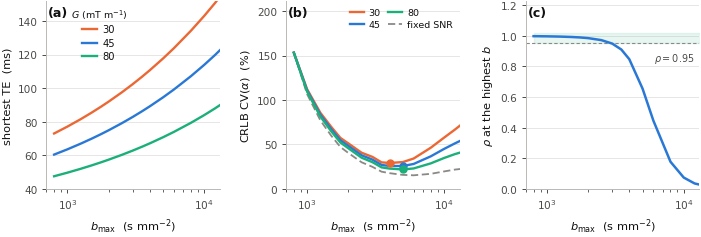

In [38]:
R4 = R7
fig, ax = plt.subplots(1, 3, figsize=(7.1, 2.5))
fig.subplots_adjust(wspace=0.38, left=0.075, right=0.995, top=0.97, bottom=0.22)
cols = {"30": C[1], "45": C[0], "80": C[2]}
for Gk in ("30", "45", "80"):
    rows = R4[Gk]
    bmx = [r["bmax"] for r in rows]
    ax[0].plot(bmx, [r["TE_ms"] for r in rows], "-", color=cols[Gk], lw=1.7,
               zorder=4, label=Gk)
    ax[1].plot(bmx, [r["cv_te"] for r in rows], "-", color=cols[Gk], lw=1.7, zorder=4,
               label=Gk)
    j = int(np.argmin([r["cv_te"] for r in rows]))
    ax[1].plot(rows[j]["bmax"], rows[j]["cv_te"], "o", color=cols[Gk], ms=5, zorder=5)
rows = R4["45"]
ax[1].plot([r["bmax"] for r in rows], [r["cv_fixed"] for r in rows],
           ls=(0, (4, 2)), color=MUTED, lw=1.3, zorder=3, label="fixed SNR")
for a_ in ax:
    a_.set_xscale("log")
    a_.set_xlabel(r"$b_{\max}$  (s mm$^{-2}$)")
    a_.set_xlim(700, 13000)
ax[0].set_ylabel("shortest TE  (ms)")
ax[0].set_ylim(40, 130)
style(ax[0]); headroom(ax[0], 0.24); panel(ax[0], "a")
ax[0].legend(loc="upper left", title=r"$G$ (mT m$^{-1}$)", title_fontsize=6.8,
             bbox_to_anchor=(0.10, 1.005))
ax[1].set_ylabel(r"CRLB CV($\alpha$)  (%)")
ax[1].set_ylim(0, 170)
style(ax[1]); headroom(ax[1], 0.24); panel(ax[1], "b")
ax[1].legend(loc="upper right", ncol=2, columnspacing=0.8, fontsize=6.8)
ax[2].plot([r["bmax"] for r in rows], [r["rho"] for r in rows], "-", color=C[0],
           lw=1.8, zorder=4)
ax[2].axhline(0.95, color=MUTED, ls=(0, (3, 2)), lw=0.8, zorder=2)
ax[2].fill_between([r["bmax"] for r in rows], 0.95, 1.02, color=C[2], alpha=0.10,
                   zorder=1)
ax[2].set_ylabel(r"$\rho$ at the highest $b$")
ax[2].set_ylim(0, 1.02)
style(ax[2]); headroom(ax[2], 0.20); panel(ax[2], "c")
ax[2].annotate(r"$\rho=0.95$", xy=(12000, 0.90), ha="right", va="top",
               fontsize=6.9, color=INK2)
savefig(fig, "fig7_bmaxcost"); plt.show()

## 18. Gaussian against Rician bound at malignant and benign values

In [39]:
R8 = []
print(f"{'values':<11}{'protocol':<12}{'SNR':>5}{'CV Rician':>11}{'CV Gauss':>10}{'too low by':>12}{'a top':>8}{'rho top':>9}")
for grp in ("malignant", "benign"):
    th = theta_ctrw(grp)
    for pk in PROTO_ORDER:
        b = np.array(PROTOCOLS[pk]["b"])
        for snr in (15, 30, 60):
            s = 1.0 / snr
            cvr = crlb(ctrw, b, th, s, jac=ctrw_jacobian)[0][2]
            cvg = crlb(ctrw, b, th, s, jac=ctrw_jacobian, gaussian=True)[0][2]
            S = S1(ctrw, np.array([b.max()]), *th)
            R8.append(dict(group=grp, protocol=pk, snr=snr, cv_rician=float(cvr), cv_gauss=float(cvg),
                           under_pct=float(100 * (cvr - cvg) / cvr), a_top=float(S * snr),
                           rho_top=float(rician_rho(S * snr))))
            print(f"{grp:<11}{PROTOCOLS[pk]['short']:<12}{snr:>5}{cvr:>11.1f}{cvg:>10.1f}"
                  f"{100*(cvr-cvg)/cvr:>11.1f}%{S*snr:>8.2f}{rician_rho(S*snr):>9.3f}")
RESULTS["R8_gaussian"] = R8

values     protocol      SNR  CV Rician  CV Gauss  too low by   a top  rho top
malignant  7-point        15       86.9      84.3        3.1%    2.13    0.872
malignant  7-point        30       42.4      42.1        0.7%    4.27    0.972
malignant  7-point        60       21.1      21.1        0.2%    8.53    0.993
malignant  9-point        15       85.0      84.2        1.0%    3.46    0.956
malignant  9-point        30       42.2      42.1        0.2%    6.92    0.989
malignant  9-point        60       21.1      21.0        0.1%   13.83    0.997
malignant  13-point       15       51.0      49.4        3.2%    2.13    0.872
malignant  13-point       30       24.9      24.7        0.7%    4.27    0.972
malignant  13-point       60       12.4      12.4        0.2%    8.53    0.993
benign     7-point        15       53.5      44.1       17.5%    0.87    0.445
benign     7-point        30       23.2      22.1        4.9%    1.74    0.802
benign     7-point        60       11.1      11.0   

## 19. Least squares against Rician maximum likelihood



In [ ]:
t0 = time.time()


def _ratio(x):
    return ive(1, x) / np.maximum(ive(0, x), 1e-300)


def rice_nll(theta, b, y, sigma):
    A = ctrw(b, *theta)
    z = y * A / sigma ** 2
    return float(np.sum(A ** 2 / (2 * sigma ** 2)
                        - (np.log(np.maximum(ive(0, z), 1e-300)) + z)))


def rice_grad(theta, b, y, sigma):
    A = ctrw(b, *theta)
    J = ctrw_jacobian(b, *theta)
    w = (A - y * _ratio(y * A / sigma ** 2)) / sigma ** 2
    return J.T @ w


def fit_rice_ml(b, y, p0, sigma, lo=CTRW_LO, hi=CTRW_HI):
    x0 = np.clip(np.asarray(p0, float), lo + 1e-9, hi - 1e-9)
    r = minimize(rice_nll, x0, args=(b, y, sigma), jac=rice_grad, method="L-BFGS-B",
                 bounds=list(zip(lo, hi)), options=dict(maxiter=500, ftol=1e-14, gtol=1e-10))
    return r.x


def run_ml(b, theta, n_total, staged, sigma=None):
    sigma = SIG if sigma is None else sigma
    key = ("rician_ml", [round(float(x), 6) for x in b], [float(x) for x in theta],
           int(n_total), bool(staged), float(sigma), SEEDS)
    return cached_blocks(key, lambda: _run_ml(b, theta, n_total, staged, sigma))


def _run_ml(b, theta, n_total, staged, sigma):
    per = n_total // len(SEEDS)
    S = ctrw(b, *theta)
    blocks = []
    for seed in SEEDS:
        rng = np.random.default_rng(seed)
        out = np.empty((per, 4))
        for i in range(per):
            y = rice_sample(S, sigma, rng)
            try:
                if staged:
                    q, _ = fit_ctrw_sequential(b, y, theta, b_lowmax=1000.0)
                    dm = q[1]
                    lo3 = np.array([CTRW_LO[0], dm, CTRW_LO[2], CTRW_LO[3]])
                    hi3 = np.array([CTRW_HI[0], dm + 1e-12, CTRW_HI[2], CTRW_HI[3]])
                    p = fit_rice_ml(b, y, [q[0], dm, theta[2], theta[3]], sigma, lo3, hi3)
                else:
                    p = fit_rice_ml(b, y, theta, sigma)
            except Exception:
                p = np.full(4, np.nan)
            out[i] = p
        blocks.append(out)
    return blocks


R9 = {}
print("Same realisations, two objective functions, malignant values, SNR 30, "
      "2000 realisations per condition.\n")
print(f"  {'protocol':<10}{'scheme':<14}{'objective':<15}{'bias%':>8}{'SD':>8}"
      f"{'RMSE%':>8}{'pinned%':>9}{'corr':>7}")
print("  " + "-" * 79)
for pk in PROTO_ORDER:
    b = np.array(PROTOCOLS[pk]["b"]); th = theta_ctrw("malignant")
    for key, scheme, obj, blocks in (
            ("ls_joint", "joint", "least squares",
             run_condition(b, th, n_total=2000, method="joint")),
            ("ml_joint", "joint", "Rician ML", run_ml(b, th, 2000, staged=False)),
            ("ls_seq", "sequential", "least squares",
             run_condition(b, th, n_total=2000, method="sequential")),
            ("ml_seq", "sequential", "Rician ML", run_ml(b, th, 2000, staged=True))):
        r = summarise(blocks, th)
        R9[f"{pk}|{key}"] = r
        a = r["alpha"]
        print(f"  {PROTOCOLS[pk]['short']:<10}{scheme:<14}{obj:<15}{a['bias_pct']:+8.1f}"
              f"{a['sd']:8.3f}{a['rmse_pct']:8.1f}{a['pinned_pct']:9.1f}"
              f"{r['corr_alpha_beta']:+7.2f}")
    print()
print(f"({time.time()-t0:.0f} s)")
RESULTS["R9_objective"] = R9

Same realisations, two objective functions, malignant values, SNR 30, 2000 realisations per condition.

  protocol  scheme        objective         bias%      SD   RMSE%  pinned%   corr
  -------------------------------------------------------------------------------


C:\Users\ASUS\AppData\Local\Temp\ipykernel_18008\3840488050.py:43: RuntimeWarning: divide by zero encountered in scalar divide
  return np.exp(-np.power(xi * t, 1.0 / alpha)) / den
C:\Users\ASUS\AppData\Local\Temp\ipykernel_18008\3840488050.py:45: IntegrationWarning: The occurrence of roundoff error is detected, which prevents 
  the requested tolerance from being achieved.  The error may be 
  underestimated.
  val, _ = quad(integ, 0.0, np.inf, limit=400, epsabs=1e-14, epsrel=1e-12)
C:\Users\ASUS\AppData\Local\Temp\ipykernel_18008\3840488050.py:45: IntegrationWarning: The algorithm does not converge.  Roundoff error is detected
  in the extrapolation table.  It is assumed that the requested tolerance
  cannot be achieved, and that the returned result (if full_output = 1) is 
  the best which can be obtained.
  val, _ = quad(integ, 0.0, np.inf, limit=400, epsabs=1e-14, epsrel=1e-12)


  7-point   joint         least squares     -12.9   0.202    24.7     45.0  -0.76
  7-point   joint         Rician ML          -9.0   0.184    21.2     33.4  -0.79
  7-point   sequential    least squares     -16.4   0.096    19.3      4.9  -0.37
  7-point   sequential    Rician ML         -12.8   0.107    17.0      6.6  -0.45



C:\Users\ASUS\AppData\Local\Temp\ipykernel_18008\1136421036.py:21: IntegrationWarning: The occurrence of roundoff error is detected, which prevents 
  the requested tolerance from being achieved.  The error may be 
  underestimated.
  val, _ = quad(integ, 0.0, np.inf, limit=400, epsabs=1e-14, epsrel=1e-12)


  9-point   joint         least squares     -16.6   0.249    30.8     43.4  -0.71
  9-point   joint         Rician ML         -13.3   0.234    27.8     36.8  -0.73
  9-point   sequential    least squares     -13.9   0.119    18.7     17.5  -0.44
  9-point   sequential    Rician ML         -10.4   0.115    15.9     19.4  -0.42

  13-point  joint         least squares     -11.6   0.199    23.7     40.1  -0.77
  13-point  joint         Rician ML          -8.6   0.180    20.7     35.8  -0.76
  13-point  sequential    least squares     -13.8   0.116    18.3     14.8  -0.59
  13-point  sequential    Rician ML          -4.4   0.083     9.7     17.3  -0.42

(622 s)


## 20. Robustness of the matrix inversion

In [41]:
print("Every reported CV recomputed seven ways.\n")
hdr = ("protocol".ljust(12) + "cond(F)".rjust(11) + "".join(f"{n:>11}" for n in
       ("pinv 1e-10", "pinv 1e-12", "pinv 1e-14", "pinv 1e-16", "eig thr", "inv", "solve"))
       + "spread".rjust(10))
print(hdr); print("-" * len(hdr))
R10 = []
for pk in PROTO_ORDER:
    b = np.array(PROTOCOLS[pk]["b"]); th = theta_ctrw("malignant")
    F = fisher(ctrw, b, th, SIG, jac=ctrw_jacobian)
    vals = []
    for rc in (1e-10, 1e-12, 1e-14, 1e-16):
        vals.append(100 * np.sqrt(np.linalg.pinv(F, rcond=rc)[2, 2]) / th[2])
    w_, V_ = np.linalg.eigh(F)
    keep = w_ > w_.max() * 1e-12
    cov = V_[:, keep] @ np.diag(1 / w_[keep]) @ V_[:, keep].T
    vals.append(100 * np.sqrt(cov[2, 2]) / th[2])
    vals.append(100 * np.sqrt(np.linalg.inv(F)[2, 2]) / th[2])
    vals.append(100 * np.sqrt(np.linalg.solve(F, np.eye(4))[2, 2]) / th[2])
    spread = (max(vals) - min(vals)) / np.mean(vals)
    R10.append(dict(protocol=pk, cond=float(w_.max() / w_.min()),
                    values=[float(v) for v in vals], spread=float(spread)))
    print(f"{PROTOCOLS[pk]['short']:<12}{w_.max()/w_.min():>11.2e}"
          + "".join(f"{v:>11.2f}" for v in vals) + f"{spread:>10.1e}")
print("\n  the seven routes agree to better than one part in 1e11 at every protocol")
RESULTS["R10_inversion"] = R10

with open(os.path.join(OUTDIR, "results.json"), "w") as f:
    json.dump(RESULTS, f, indent=1)
print("\n  wrote nb_output/results.json")

Every reported CV recomputed seven ways.

protocol        cond(F) pinv 1e-10 pinv 1e-12 pinv 1e-14 pinv 1e-16    eig thr        inv      solve    spread
--------------------------------------------------------------------------------------------------------------
7-point        9.60e+07      42.42      42.42      42.42      42.42      42.42      42.42      42.42   5.9e-14
9-point        8.32e+07      42.18      42.18      42.18      42.18      42.18      42.18      42.18   3.7e-12
13-point       3.45e+07      24.88      24.88      24.88      24.88      24.88      24.88      24.88   8.0e-12

  the seven routes agree to better than one part in 1e11 at every protocol

  wrote nb_output/results.json


## 21. Supplementary figures

### Figure S1: boundary terminations across the assumed parameter grid

  saved nb_output/figS1_grid_pinning.png


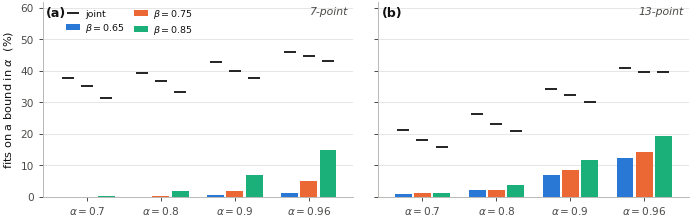

In [42]:
"""Boundary terminations across the assumed (alpha, beta) grid."""
fig, ax = plt.subplots(1, 2, figsize=(7.1, 2.6), sharey=True)
fig.subplots_adjust(wspace=0.08, left=0.085, right=0.995, top=0.97, bottom=0.22)
alphas = (0.70, 0.80, 0.90, 0.96)
betas = (0.65, 0.75, 0.85)
na = len(alphas)
w = 0.26
for pi, pk in enumerate(("Ji2023_7", "Lin2023_13")):
    A = ax[pi]
    for bi, bt in enumerate(betas):
        vals = [R5[f"{pk}|{a}|{bt}|sequential"]["alpha"]["pinned_pct"] for a in alphas]
        A.bar(np.arange(na) + (bi - 1) * w, vals, w * 0.88, color=C[bi], zorder=3,
              label=rf"$\beta={bt}$" if pi == 0 else None, linewidth=0)
    for bi, bt in enumerate(betas):
        vals = [R5[f"{pk}|{a}|{bt}|joint"]["alpha"]["pinned_pct"] for a in alphas]
        A.plot(np.arange(na) + (bi - 1) * w, vals, "_", color=INK, ms=8, mew=1.3,
               zorder=5, label="joint" if (pi == 0 and bi == 0) else None)
    A.set_xticks(range(na))
    A.set_xticklabels([rf"$\alpha={a}$" for a in alphas])
    A.set_xlim(-0.6, na - 0.4)
    A.set_ylim(0, 50)
    style(A)
    headroom(A, 0.24)
    panel(A, "ab"[pi])
    A.text(0.985, 0.975, SHORT[pk], transform=A.transAxes, ha="right", va="top",
           fontsize=7.8, color=INK2, style="italic")
ax[0].set_ylabel(r"fits on a bound in $\alpha$  (%)")
ax[0].legend(loc="upper left", ncol=2, bbox_to_anchor=(0.055, 1.005),
             columnspacing=0.9, fontsize=6.8)
savefig(fig, "figS1_grid_pinning"); plt.show()

### Figure S2: fitted accuracy of all three parameters under truncation

  saved nb_output/figS2_bmax_allparams.png


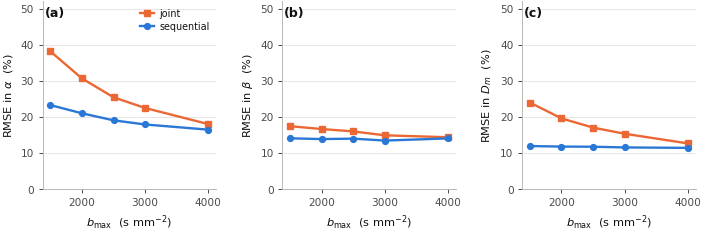

In [43]:
"""Fitted accuracy of all three CTRW parameters as the acquisition is truncated."""
bm = [1500., 2000., 2500., 3000., 4000.]
fig, ax = plt.subplots(1, 3, figsize=(7.1, 2.5))
fig.subplots_adjust(wspace=0.38, left=0.075, right=0.995, top=0.97, bottom=0.22)
for j, (key, lab, lim) in enumerate((("alpha", r"$\alpha$", 42),
                                     ("beta", r"$\beta$", 42),
                                     ("Dm", r"$D_m$", 42))):
    for mi, (meth, lsty, col) in enumerate((("joint", "s-", C[1]),
                                            ("sequential", "o-", C[0]))):
        ax[j].plot(bm, [R6[f"trunc|{b:.0f}|{meth}"][key]["rmse_pct"] for b in bm],
                   lsty, color=col, lw=1.7, ms=4.2, zorder=4,
                   label=("joint" if meth == "joint" else "sequential")
                   if j == 0 else None)
    ax[j].set_xlabel(r"$b_{\max}$  (s mm$^{-2}$)")
    ax[j].set_ylabel(rf"RMSE in {lab}  (%)")
    ax[j].set_ylim(0, lim)
    style(ax[j])
    headroom(ax[j], 0.24)
    panel(ax[j], "abc"[j])
ax[0].legend(loc="upper right", fontsize=6.9)
savefig(fig, "figS2_bmax_allparams"); plt.show()

### Figures S3 and S4: bias and boundary fraction over the rectangle

  saved nb_output/figS3_grid_sequential.png


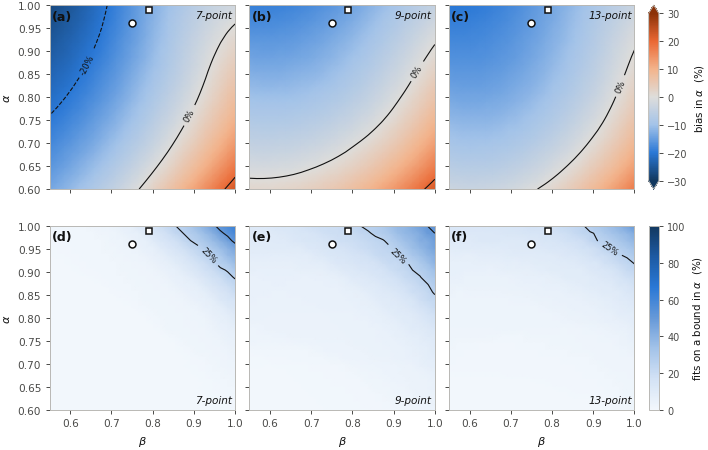

  saved nb_output/figS4_grid_joint.png


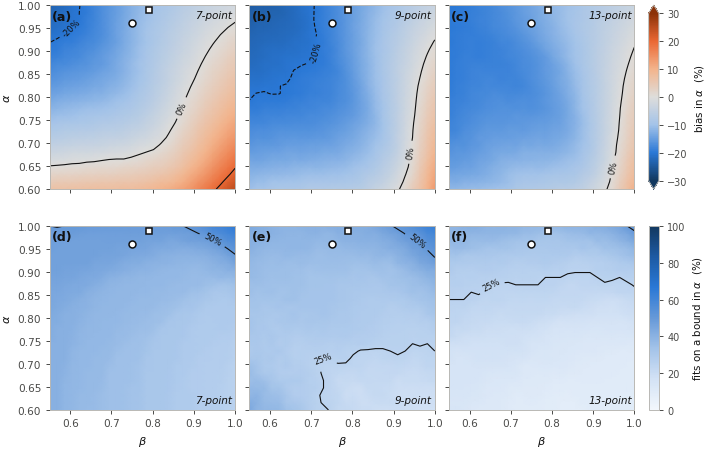

In [44]:
"""Bias and boundary fraction over the rectangle, one figure per fitting scheme."""
DIV = LinearSegmentedColormap.from_list(
    "div", ["#12385f", "#2a78d6", "#a3c3e9", "#dedddb", "#f3b48c", "#eb6834", "#8c3208"])
Ag = np.array(R3B["alpha"]); Bg = np.array(R3B["beta"])

def grid_figure(scheme, fname):
    fig = plt.figure(figsize=(7.1, 4.55))
    gs = fig.add_gridspec(2, 4, width_ratios=[1, 1, 1, 0.055],
                          left=0.072, right=0.93, top=0.975, bottom=0.085,
                          wspace=0.10, hspace=0.20)
    spec = [("bias", DIV, -30.0, 30.0, [-20, 0, 20], r"bias in $\alpha$  (%)", "abc"),
            ("pin", SEQ, 0.0, 100.0, [25, 50, 75], r"fits on a bound in $\alpha$  (%)", "def")]
    for r, (key, cmap, vmin, vmax, lv, label, letters) in enumerate(spec):
        for i, pk in enumerate(PROTO_ORDER):
            ax = fig.add_subplot(gs[r, i])
            Z = np.array(R3B["surfaces"][f"{pk}|{scheme}"][key])
            im = ax.pcolormesh(Bg, Ag, np.clip(Z, vmin, vmax), cmap=cmap, vmin=vmin,
                               vmax=vmax, shading="gouraud", rasterized=True)
            cs = ax.contour(Bg, Ag, Z, levels=lv, colors=["#111111"], linewidths=0.8)
            ax.clabel(cs, inline=True, fontsize=6.0, fmt="%d%%")
            for grp, mk in (("malignant", "o"), ("benign", "s")):
                th = theta_ctrw(grp)
                ax.plot(th[3], th[2], mk, mfc="white", mec="#111111", ms=5.0, mew=1.1, zorder=5)
            ax.set_xticks([0.6, 0.7, 0.8, 0.9, 1.0])
            if r == 1:
                ax.set_xlabel(r"$\beta$")
            else:
                ax.set_xticklabels([])
            if i:
                ax.set_yticklabels([])
            else:
                ax.set_ylabel(r"$\alpha$")
            panel(ax, letters[i])
            y_, va_ = (0.975, "top") if r == 0 else (0.025, "bottom")
            ax.text(0.985, y_, SHORT[pk], transform=ax.transAxes, ha="right",
                    va=va_, fontsize=7.6, color=INK, zorder=6, style="italic")
        cax = fig.add_subplot(gs[r, 3])
        cb = fig.colorbar(im, cax=cax, extend="both" if r == 0 else "neither")
        cb.set_label(label, labelpad=4, fontsize=7.4)
        cb.ax.tick_params(labelsize=7.0)
    savefig(fig, fname); plt.show()

grid_figure("sequential", "figS3_grid_sequential")
grid_figure("joint", "figS4_grid_joint")

### Figures S5 and S6: bias and boundary fraction at the benign D_m

  saved nb_output/figS5_grid_sequential_benignDm.png


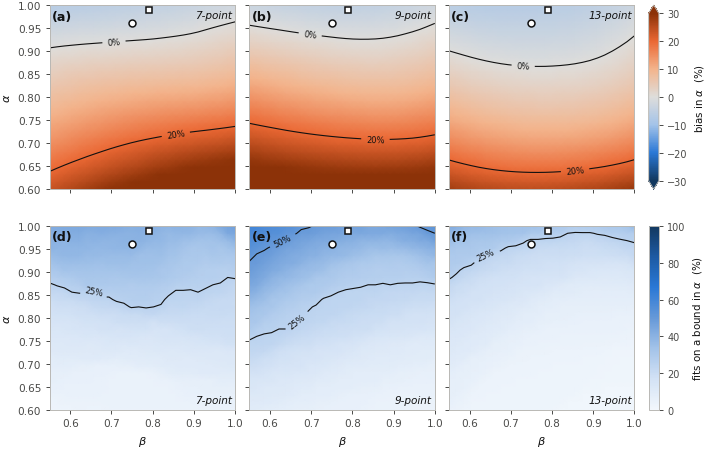

  saved nb_output/figS6_grid_joint_benignDm.png


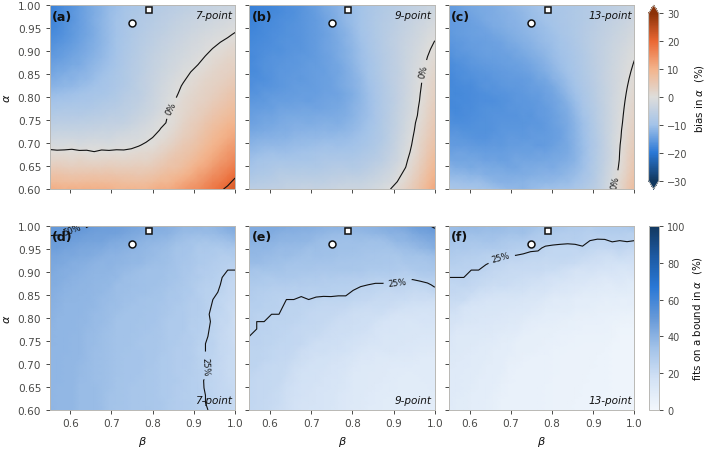

In [45]:
_R3B_malignant = R3B
R3B = RESULTS["R3B_grid_mc_benignDm"]
grid_figure("sequential", "figS5_grid_sequential_benignDm")
grid_figure("joint", "figS6_grid_joint_benignDm")
R3B = _R3B_malignant

## 22. result

In [46]:
def _plain(o):
    if isinstance(o, dict):
        return {str(k): _plain(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [_plain(v) for v in o]
    if isinstance(o, np.ndarray):
        return _plain(o.tolist())
    if isinstance(o, (np.floating, np.integer)):
        return o.item()
    return o
json.dump(_plain(RESULTS), open(os.path.join(OUTDIR, "results.json"), "w"))
print("saved", os.path.join(OUTDIR, "results.json"), "with", len(RESULTS), "result blocks")

saved nb_output\results.json with 24 result blocks
